# Домашнее задание 1. Персональные top-10 рекомендации: Amazon Reviews 2023, Video Games

Пять моделей реализованы с нуля в `models/`. Их персональные top-10 рекомендации сравниваются по воспроизводимому протоколу:

| # | Модель | Файл | Что учитывает |
|---|---|---|---|
| 1 | Item-based kNN (asymmetric cosine + shrinkage, давность в профиле пользователя) | `models/item_knn.py` | совместные покупки |
| 2 | iALS (Hu, Koren, Volinsky, 2008), решатель — сопряжённые градиенты | `models/ials.py` | неявный отклик |
| 3 | EASE (Steck, 2019) | `models/ease.py` | item-item регрессия в замкнутой форме |
| 4 | Factorization Machine + BPR с метапризнаками и временным контекстом | `models/fm.py` | ID, платформа, тип, издатель, цена, ESRB, профиль пользователя, «возраст» и свежая популярность товара |
| 5 | timeSVD++ (Koren, 2009) + член для пропущенных данных (Steck, 2010) | `models/time_svdpp.py` | оценки, дрейф смещений и факторов во времени |

Бейзлайны для калибровки: случайный, популярный и популярный с затуханием по времени (`models/baselines.py`). Общий код вынесен в `utils/`: загрузка данных, временной сплит, метрики, оценка, подбор гиперпараметров. Корректность моделей проверяется юнит-тестами в `tests/`: каждая модель сверяется с прямым медленным вычислением своей формулы.

## Как запустить

Все команды выполняются из директории `hw1/` репозитория. ФИО, датасет и ссылки на него — в `DATA.md`.

1. **Окружение** (Python 3.12):
   ```bash
   cd hw1
   python -m venv .venv && source .venv/bin/activate
   pip install -r requirements.txt
   # Linux + NVIDIA (драйвер >= 525): torch с CUDA из индекса PyTorch
   pip install torch==2.14.1 --index-url https://download.pytorch.org/whl/cu126
   ```
2. **Данные** скачиваются первой ячейкой раздела 1 из первоисточника (McAuley Lab, UCSD) в `hw1/data/raw/`, всего ~116 МБ. Вручную:
   ```bash
   mkdir -p data/raw && cd data/raw
   wget https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/benchmark/5core/rating_only/Video_Games.csv.gz
   wget https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/meta_categories/meta_Video_Games.jsonl.gz
   ```
   Контрольные суммы SHA-256 выводятся в ноутбуке.
3. **Запуск**: `Run All` или
   ```bash
   jupyter nbconvert --to notebook --execute --inplace experiments.ipynb --ExecutePreprocessor.timeout=-1
   ```
   Модели и ранжирование top-K работают на GPU, если он есть (`DEVICE`). Без GPU всё работает на CPU, но медленнее. Сохранённый прогон занял ≈ 1 ч 20 мин на общей A100 40 ГБ при 4 CPU-потоках; GPU-память резервируется один раз (`GPU_RESERVE_GB`), потому что карта общая.
4. **Быстрый перезапуск**: при `RUN_SEARCH = False` подбор гиперпараметров не повторяется, а лучшие конфигурации берутся из `results/tuning/*.json`, которые сохранил полный прогон.
5. **Воспроизводимость**: `SEED = 42` для numpy, torch, Optuna TPE и bootstrap. Включены `torch.use_deterministic_algorithms(True)` и `CUBLAS_WORKSPACE_CONFIG`. Каждая модель после подбора переобучается с выбранными параметрами, и ноутбук проверяет, что метрика на validation совпадает с найденной при подборе.
6. **Тесты**: `pytest -q tests`.

In [1]:
import os

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")  # deterministic cuBLAS; set before CUDA init

import json
import logging
import sys
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm inside optuna, no ipywidgets

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
from IPython.display import display

from models import MODEL_REGISTRY, build_model
from utils.data import MS_PER_DAY, DataConfig, download_dataset, encode, file_sha256, load_item_meta, load_ratings
from utils.features import FeatureConfig, build_item_features, item_first_day
from utils.metrics import bootstrap_ci, paired_bootstrap
from utils.split import SplitConfig, day_of, make_fit_data, make_target, temporal_split
from utils.tuning import (
    EpochMonitor, TuningConfig, best_params, fit_evaluate, load_study, release_memory, save_study, topn_score, tune,
)

SEED = 42
RUN_SEARCH = True  # False: reuse the hyperparameters saved in results/tuning/
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_THREADS = 4

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
torch.set_num_threads(N_THREADS)
GPU_RESERVE_GB = 6.5  # peak need (EASE: two 24k x 24k float32 matrices); the GPU is shared with other jobs
if DEVICE == "cuda":
    # Allocate once and drop: the block stays in PyTorch's cache for the whole run, so other
    # jobs on the shared GPU cannot take the memory between models.
    torch.empty(int(GPU_RESERVE_GB * 2**30), dtype=torch.uint8, device=DEVICE)
logging.basicConfig(  # stdout: Jupyter paints stderr red, these are progress messages
    level=logging.WARNING, format="%(asctime)s %(name)s: %(message)s", datefmt="%H:%M:%S", stream=sys.stdout
)
Path("logs").mkdir(exist_ok=True)
_file_log = logging.FileHandler("logs/run.log")  # progress of long runs (nbconvert shows outputs only at the end)
_file_log.setFormatter(logging.Formatter("%(asctime)s %(name)s: %(message)s", datefmt="%H:%M:%S"))
logging.getLogger().addHandler(_file_log)
for name in ("utils", "experiments"):
    logging.getLogger(name).setLevel(logging.INFO)
log = logging.getLogger("experiments")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

RESULTS = Path("results")
(RESULTS / "tuning").mkdir(parents=True, exist_ok=True)
DATA_CFG = DataConfig()
SPLIT_CFG = SplitConfig(val_start="2021-07-01", test_start="2022-07-01", relevance_threshold=4.0)
FEATURE_CFG = FeatureConfig()
TUNE_CFG = TuningConfig(metric="ndcg@10", k=10, seed=SEED, patience=2, device=DEVICE)
K = TUNE_CFG.k
print(f"torch {torch.__version__}; device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print(SPLIT_CFG, FEATURE_CFG, TUNE_CFG, sep="\n")

torch 2.14.1+cu126; device: cuda (NVIDIA A100-PCIE-40GB)
SplitConfig(val_start='2021-07-01', test_start='2022-07-01', relevance_threshold=4.0)
FeatureConfig(min_platform_items=20, min_type_items=20, min_store_items=10, n_price_bins=10)
TuningConfig(metric='ndcg@10', k=10, seed=42, patience=2, batch_size=2048, device='cuda')


## 1. Данные

**Датасет**: *Amazon Reviews 2023*, категория **Video Games** (Hou et al., 2024, «Bridging Language and Items for Retrieval and Recommendation»). Страница первоисточника: https://amazon-reviews-2023.github.io/ ; файлы лежат на сервере McAuley Lab (UCSD). Используются два официальных файла:

* `benchmark/5core/rating_only/Video_Games.csv.gz` — отзывы в официальной 5-core выборке: у каждого пользователя и каждого товара не меньше 5 отзывов. Поля: `user_id` (анонимизированный id автора), `parent_asin` (id товара, варианты одного товара объединены), `rating` (1–5 звёзд), `timestamp` (Unix-время в мс).
* `raw/meta_categories/meta_Video_Games.jsonl.gz` — метаданные товаров: `title`, `categories` (путь в каталоге, например `Video Games > PlayStation 4 > Games`), `store` (бренд или издатель), `price`, `details` (ESRB, дата появления), `description`, `features` и агрегаты `average_rating`, `rating_number`.

**Взаимодействие.** Отзыв с оценкой. На Amazon его обычно оставляют после покупки, поэтому отзыв служит наблюдаемым сигналом «пользователь купил товар», а оценка показывает, насколько товар понравился.

**Что рекомендуем.** Каждому пользователю в момент $t_{rec}$ (граница периода) показываем 10 товаров каталога Video Games (игры, консоли, аксессуары), которых он ещё не покупал.

**Что релевантно.** Товар, который пользователь купил в оцениваемом периоде и оценил на **4–5 звёзд**: купил и остался доволен. Критерий одинаков для всех моделей, хотя обучаются они на разных таргетах (бинарный факт покупки, BPR-пары, явные оценки).

In [2]:
ratings_path, meta_path = download_dataset(DATA_CFG)
files = pd.DataFrame(
    [
        {"file": path.name, "MB": round(path.stat().st_size / 2**20, 1), "sha256": file_sha256(path), "url": url}
        for path, url in [(ratings_path, DATA_CFG.ratings_url), (meta_path, DATA_CFG.meta_url)]
    ]
)
files

21:58:06 utils.data: Found data/raw/Video_Games.csv.gz (12.2 MB), skipping download
21:58:06 utils.data: Found data/raw/meta_Video_Games.jsonl.gz (98.3 MB), skipping download


,file,MB,sha256,url
0,Video_Games.csv.gz,12.2,a2bde5f3b945960d161538c200dd87845e6ee471b46da96410dde61613c6901c,https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/benchmark/5core/rating_only/Video_Games.csv.gz
1,meta_Video_Games.jsonl.gz,98.3,ced9696b0874121327a438bfe9d3d01aba45da158e58f94f4920352d75fc1fc9,https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/meta_categories/meta_Video_Games.jsonl.gz


In [3]:
ratings = load_ratings(ratings_path)
meta = load_item_meta(meta_path, keep=set(ratings["parent_asin"].unique()))
display(ratings.head())
display(meta.drop(columns=["average_rating", "rating_number"]).head(3))
n_users, n_items = ratings["user_id"].nunique(), ratings["parent_asin"].nunique()
when = pd.to_datetime(ratings["timestamp"], unit="ms")
pd.Series(
    {
        "взаимодействий (отзывов)": len(ratings),
        "пользователей": n_users,
        "товаров": n_items,
        "товаров с метаданными": meta["parent_asin"].nunique(),
        "первый отзыв": when.min().date(),
        "последний отзыв": when.max().date(),
        "плотность матрицы, %": round(100 * len(ratings) / (n_users * n_items), 4),
        "среднее взаимодействий на пользователя": round(len(ratings) / n_users, 2),
        "среднее взаимодействий на товар": round(len(ratings) / n_items, 2),
    },
    name="исходный объём",
).to_frame()

21:58:14 utils.data: Parsed metadata for 25612 items


,user_id,parent_asin,rating,timestamp
0,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B08R5B7YS4,1.0,1611459666223
1,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0863MT183,4.0,1613701986538
2,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B08P8P7686,5.0,1613702112995
3,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0B7LV3DN2,4.0,1617641445475
4,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B09WMQ6DXG,5.0,1620231368468


,parent_asin,title,main_category,category_path,platform,item_type,store,price,esrb,date_first_available,description_len,n_feature_bullets
0,B00Z9TLVK0,NBA 2K17 - Early Tip Off Edition - PlayStation 4,Video Games,Video Games > PlayStation 4 > Games,PlayStation 4,Games,2K,58.00,Everyone,"April 13, 2016",341,10
1,B07H93H878,eXtremeRate Soft Touch Top Shell Front Housing Faceplate Replacement Parts with Side Rails Panel for Xbox One X & On...,Video Games,"Video Games > Xbox One > Accessories > Faceplates, Protectors & Skins",Xbox One,"Faceplates, Protectors & Skins",eXtremeRate,17.59,unknown,"September 11, 2017",0,5
2,B00006969T,Konami Collector's Series: Castlevania & Contra - PC,Video Games,Video Games > PC > Games,PC,Games,Square Enix,NaN,Everyone,"December 13, 2002",153,4


,исходный объём
взаимодействий (отзывов),814586
пользователей,94762
товаров,25612
товаров с метаданными,25612
первый отзыв,1999-10-22
последний отзыв,2023-09-02
"плотность матрицы, %",0.0336
среднее взаимодействий на пользователя,8.6
среднее взаимодействий на товар,31.8


## 2. EDA и подготовка данных

### 2.1 Пропуски, дубликаты, корректность значений

In [4]:
checks = pd.Series(
    {
        "пропуски в ratings": int(ratings.isna().sum().sum()),
        "полные дубликаты строк": int(ratings.duplicated().sum()),
        "повторные пары (user, item)": int(ratings.duplicated(["user_id", "parent_asin"]).sum()),
        "оценки вне {1,...,5}": int((~ratings["rating"].isin([1, 2, 3, 4, 5])).sum()),
        "товары без записи в метаданных": int(n_items - meta["parent_asin"].nunique()),
        "пары (user, timestamp) с >1 отзывом": int(ratings.duplicated(["user_id", "timestamp"]).sum()),
    },
    name="количество",
).to_frame()
meta_missing = pd.Series(
    {
        "title": (meta["title"] == "").mean(),
        "путь категорий": (meta["category_path"] == "").mean(),
        "платформа (из пути)": (meta["platform"] == "unknown").mean(),
        "тип товара (из пути)": (meta["item_type"] == "unknown").mean(),
        "store": (meta["store"] == "unknown").mean(),
        "price": meta["price"].isna().mean(),
        "ESRB (details.Rated)": (meta["esrb"] == "unknown").mean(),
        "description": (meta["description_len"] == 0).mean(),
    }
).mul(100).round(1).rename("пропусков в метаданных, %").to_frame()
display(checks, meta_missing)

,количество
пропуски в ratings,0
полные дубликаты строк,0
"повторные пары (user, item)",0
"оценки вне {1,...,5}",0
товары без записи в метаданных,0
"пары (user, timestamp) с >1 отзывом",61


,"пропусков в метаданных, %"
title,0.0
путь категорий,3.4
платформа (из пути),4.3
тип товара (из пути),9.6
store,0.5
price,33.1
ESRB (details.Rated),52.4
description,26.6


### 2.2 Оценки

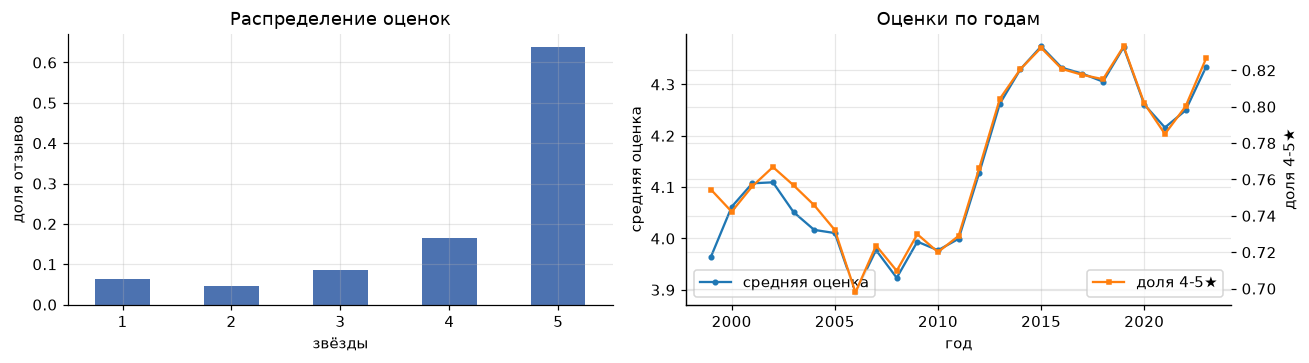

доля оценок 4-5★: 0.804; средняя оценка 4.27


In [5]:
year = when.dt.year
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
ratings["rating"].astype(int).value_counts(normalize=True).sort_index().plot.bar(ax=axes[0], color="#4C72B0", rot=0)
axes[0].set(title="Распределение оценок", xlabel="звёзды", ylabel="доля отзывов")
by_year = ratings.groupby(year)["rating"].agg(mean="mean", positive=lambda r: (r >= 4).mean())
by_year["mean"].plot(ax=axes[1], marker="o", ms=3, label="средняя оценка")
axes[1].set(title="Оценки по годам", xlabel="год", ylabel="средняя оценка")
ax2 = axes[1].twinx()
by_year["positive"].plot(ax=ax2, color="C1", marker="s", ms=3, label="доля 4-5★")
ax2.set_ylabel("доля 4-5★")
axes[1].legend(loc="lower left"); ax2.legend(loc="lower right")
plt.tight_layout(); plt.show()
print(f"доля оценок 4-5★: {(ratings['rating'] >= 4).mean():.3f}; средняя оценка {ratings['rating'].mean():.2f}")

### 2.3 Активность пользователей, популярность товаров, разреженность

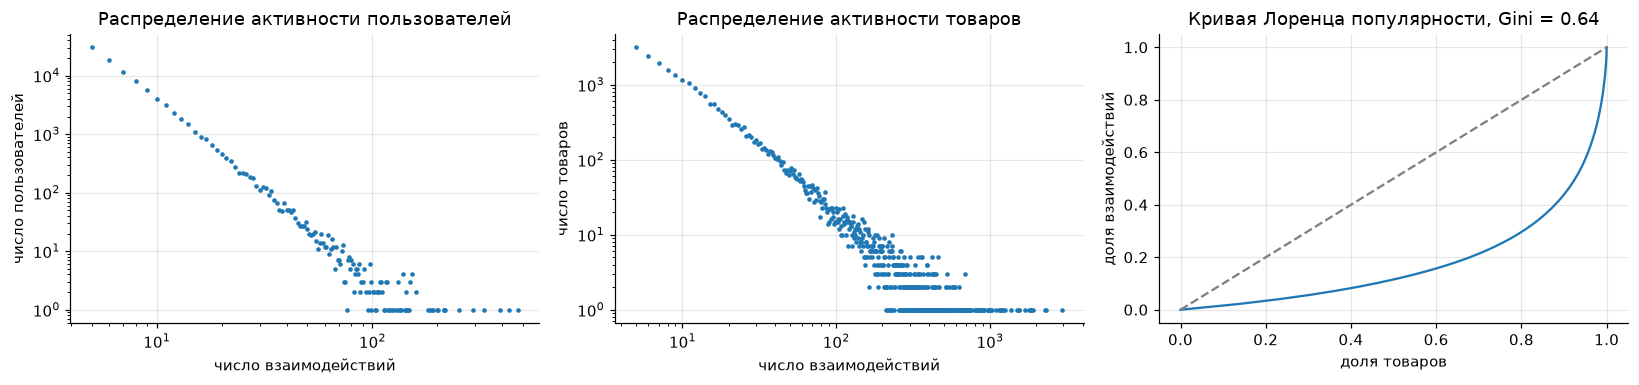

квантиль числа взаимодействий,0.25,0.50,0.75,0.90,0.99,1.00
пользователь,5.0,6.0,9.0,14.0,38.00,473.0
товар,7.0,12.0,26.0,64.0,340.89,2955.0


доля взаимодействий у 1% самых популярных товаров: 0.186; у 20%: 0.704


In [6]:
user_cnt = ratings.groupby("user_id").size()
item_cnt = ratings.groupby("parent_asin").size()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, cnt, title in [(axes[0], user_cnt, "пользователей"), (axes[1], item_cnt, "товаров")]:
    vc = cnt.value_counts().sort_index()
    ax.loglog(vc.index, vc.values, ".", ms=4)
    ax.set(title=f"Распределение активности {title}", xlabel="число взаимодействий", ylabel=f"число {title}")
cum = np.cumsum(np.sort(item_cnt.to_numpy())) / item_cnt.sum()
gini = 1 - 2 * np.trapezoid(cum, dx=1 / len(cum))
axes[2].plot(np.linspace(0, 1, len(cum)), cum)
axes[2].plot([0, 1], [0, 1], "--", c="gray")
axes[2].set(title=f"Кривая Лоренца популярности, Gini = {gini:.2f}", xlabel="доля товаров", ylabel="доля взаимодействий")
plt.tight_layout(); plt.show()
top1 = item_cnt.sort_values(ascending=False)
quant = pd.DataFrame({"пользователь": user_cnt.quantile([0.25, 0.5, 0.75, 0.9, 0.99, 1.0]),
                      "товар": item_cnt.quantile([0.25, 0.5, 0.75, 0.9, 0.99, 1.0])})
display(quant.rename_axis("квантиль числа взаимодействий").T)
print(f"доля взаимодействий у 1% самых популярных товаров: {top1.iloc[: len(top1) // 100].sum() / len(ratings):.3f}; "
      f"у 20%: {top1.iloc[: len(top1) // 5].sum() / len(ratings):.3f}")

### 2.4 Динамика во времени

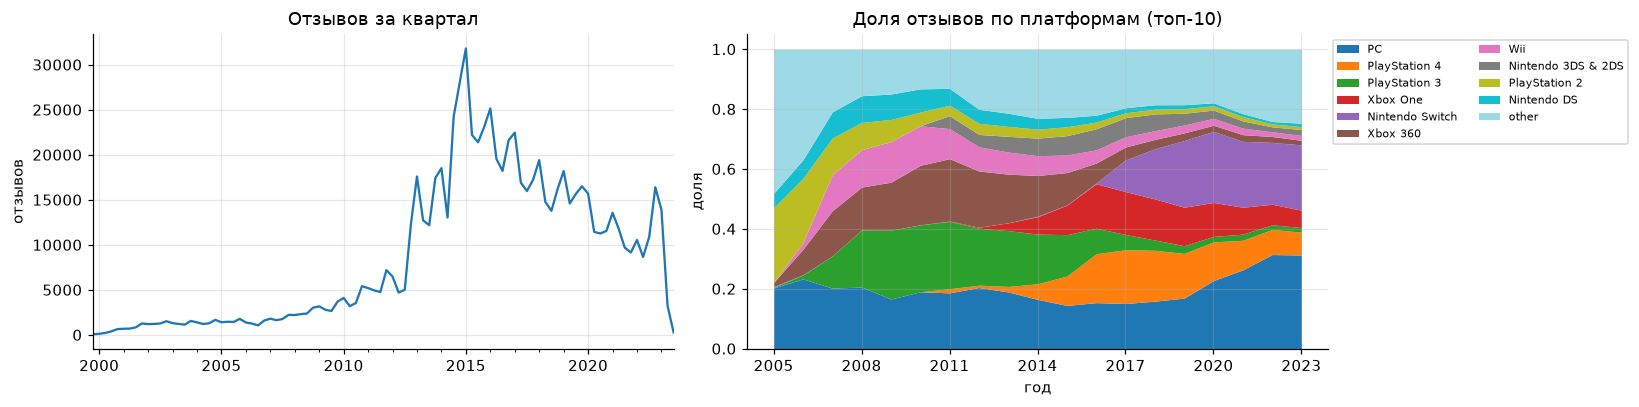

In [7]:
platform_of = meta.set_index("parent_asin")["platform"]
plat = ratings["parent_asin"].map(platform_of)
top_plat = plat[plat != "unknown"].value_counts().index[:10]
share = pd.crosstab(year, plat.where(plat.isin(top_plat), "other"), normalize="index")
share = share.loc[share.index >= 2005, list(top_plat) + ["other"]]
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
when.dt.to_period("Q").value_counts().sort_index().plot(ax=axes[0])
axes[0].set(title="Отзывов за квартал", xlabel="", ylabel="отзывов")
share.plot.area(ax=axes[1], stacked=True, cmap="tab20", lw=0)
axes[1].set_xticks(range(2005, 2024, 3))
axes[1].set(title="Доля отзывов по платформам (топ-10)", xlabel="год", ylabel="доля")
axes[1].legend(ncol=2, fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout(); plt.show()

### 2.5 Метаданные

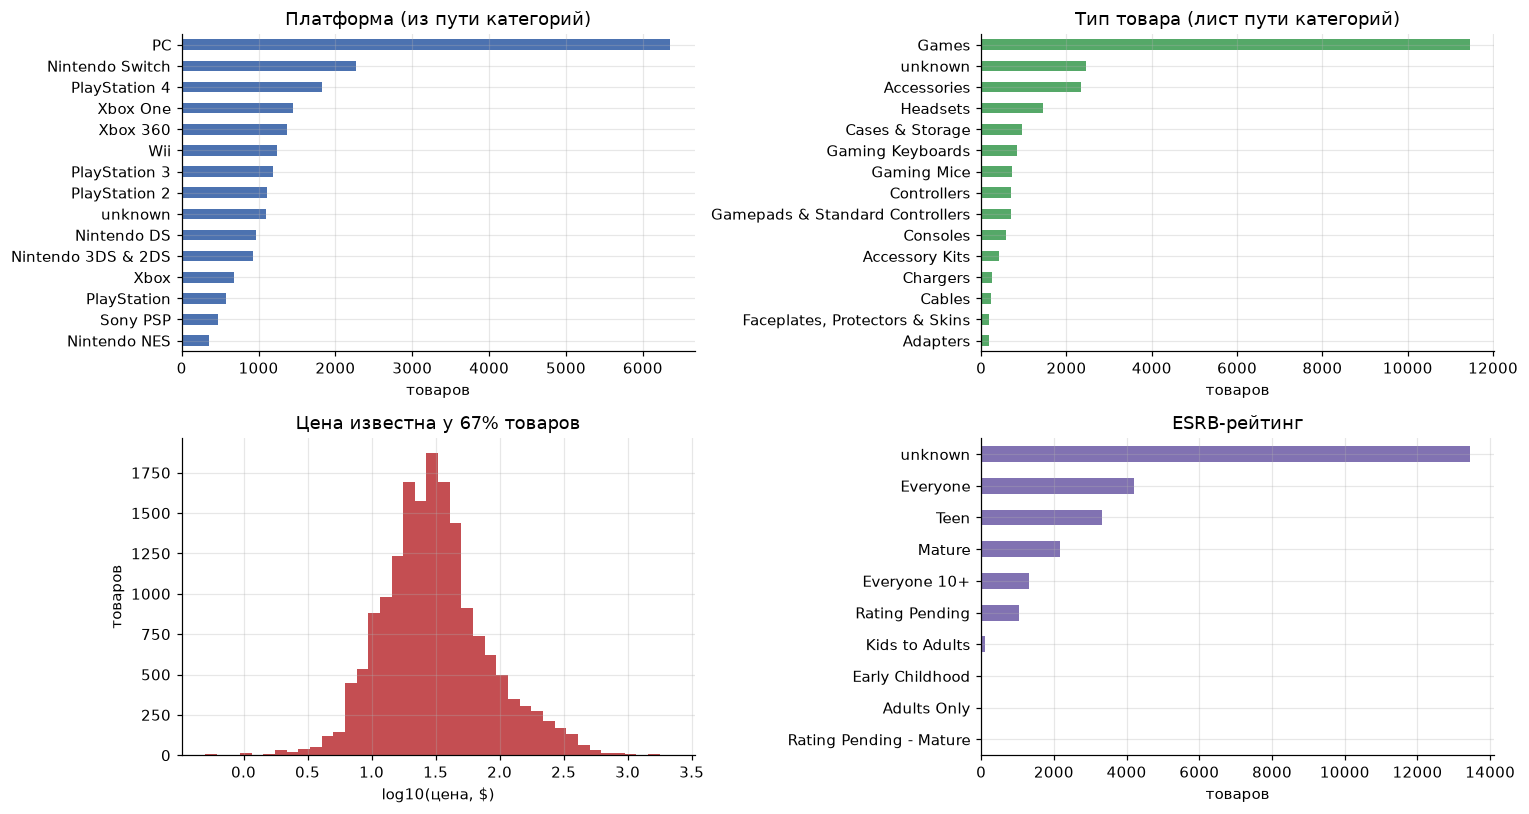

уникальных платформ: 79, типов: 67, store: 3906; main_category: {'Video Games': 17930, 'Computers': 3263, 'All Electronics': 2645, 'unknown': 514}


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))
meta["platform"].value_counts().head(15)[::-1].plot.barh(ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set(title="Платформа (из пути категорий)", xlabel="товаров", ylabel="")
meta["item_type"].value_counts().head(15)[::-1].plot.barh(ax=axes[0, 1], color="#55A868")
axes[0, 1].set(title="Тип товара (лист пути категорий)", xlabel="товаров", ylabel="")
np.log10(meta["price"].dropna().clip(lower=0.5)).plot.hist(bins=40, ax=axes[1, 0], color="#C44E52")
axes[1, 0].set(title=f"Цена известна у {meta['price'].notna().mean():.0%} товаров", xlabel="log10(цена, $)", ylabel="товаров")
meta["esrb"].value_counts()[::-1].plot.barh(ax=axes[1, 1], color="#8172B2")
axes[1, 1].set(title="ESRB-рейтинг", xlabel="товаров", ylabel="")
plt.tight_layout(); plt.show()
print(f"уникальных платформ: {meta['platform'].nunique()}, типов: {meta['item_type'].nunique()}, "
      f"store: {meta['store'].nunique()}; main_category: {meta['main_category'].value_counts().head(4).to_dict()}")

Насколько метаданные **информативны для персонализации**? Проверим, «лоялен» ли пользователь платформе и издателю. Для каждого пользователя считаем долю его покупок, пришедшуюся на самую частую у него платформу (store). Затем сравниваем с тем же показателем после случайной перестановки меток товаров между взаимодействиями: так выглядели бы данные, если бы платформа не зависела от пользователя.

In [9]:
def top_share(users: pd.Series, labels: pd.Series) -> float:
    counts = pd.DataFrame({"u": users.to_numpy(), "l": labels.to_numpy()}).groupby(["u", "l"]).size()
    return float((counts.groupby(level=0).max() / counts.groupby(level=0).sum()).mean())

rng_perm = np.random.default_rng(SEED)
store = ratings["parent_asin"].map(meta.set_index("parent_asin")["store"])
loyalty = []
for name, labels in [("платформа", plat), ("store", store)]:
    known = labels != "unknown"
    users_k, labels_k = ratings.loc[known, "user_id"], labels[known]
    loyalty.append({
        "признак": name,
        "доля топ-значения у пользователя": top_share(users_k, labels_k),
        "то же при случайной перестановке": top_share(users_k, pd.Series(rng_perm.permutation(labels_k.to_numpy()))),
    })
pd.DataFrame(loyalty).round(3)

,признак,доля топ-значения у пользователя,то же при случайной перестановке
0,платформа,0.500,0.309
1,store,0.311,0.215


### 2.6 Жизненный цикл товара

Сколько отзывов товар собирает вскоре после появления? Берём товары, у которых первый отзыв пришёлся на 2010–2019 годы, чтобы у каждого было не меньше 3.5 лет наблюдений, и смотрим, на каком «возрасте» товара (время от его первого отзыва) пишутся отзывы.

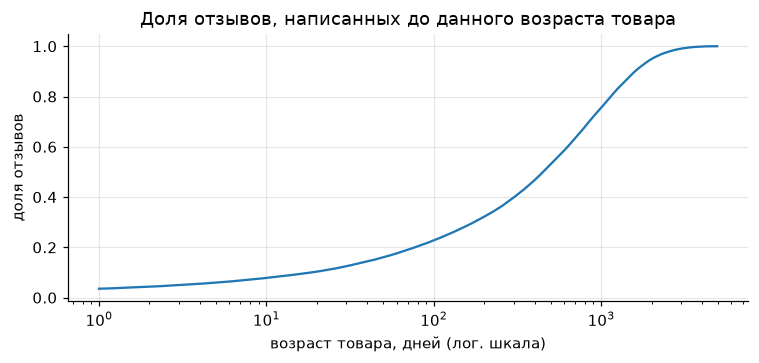

,<= 30 дней,<= 90 дней,<= 365 дней,<= 1095 дней
доля отзывов,0.125,0.216,0.444,0.786


In [10]:
first_ts = ratings.groupby("parent_asin")["timestamp"].transform("min")
age_days = (ratings["timestamp"] - first_ts) / MS_PER_DAY
first_year = pd.to_datetime(first_ts, unit="ms").dt.year
mask = first_year.between(2010, 2019)
ages = age_days[mask]
fig, ax = plt.subplots(figsize=(7, 3.4))
grid = np.logspace(0, np.log10(ages.max() + 1), 200)
ax.semilogx(grid, [(ages <= g).mean() for g in grid])
ax.set(title="Доля отзывов, написанных до данного возраста товара", xlabel="возраст товара, дней (лог. шкала)", ylabel="доля отзывов")
plt.tight_layout(); plt.show()
pd.Series({f"<= {d} дней": (ages <= d).mean() for d in (30, 90, 365, 3 * 365)}, name="доля отзывов").round(3).to_frame().T

### 2.7 Итоги EDA и подготовка данных

* **Качество данных.** Пропусков, дубликатов строк, повторных пар (user, item) и оценок вне шкалы 1–5 нет. Метаданные есть у всех 25 612 товаров. В 61 случае пользователь оставил несколько отзывов в одну миллисекунду; это пренебрежимо мало, такие отзывы оставлены.
* **Разреженность и длинные хвосты.** Плотность матрицы 0.034%. У медианного пользователя 6 отзывов (у 90% не больше 14), у медианного товара 12. На 1% самых популярных товаров приходится 18.6% взаимодействий, на 20% — 70% (Gini 0.64). Поэтому абсолютные значения top-10 метрик будут низкими, а «популярное» окажется сильным бейзлайном.
* **Оценки смещены вверх.** 80.4% отзывов имеют 4–5★, средняя оценка 4.27. Порог релевантности 4 отсекает лишь пятую часть покупок, а модели неявного отклика учатся на всех покупках. Средняя оценка дрейфует во времени: около 4.0 в 2005–2011 годах и 4.3–4.4 после 2013-го. Это аргумент в пользу временных смещений в timeSVD++.
* **Время.** Число отзывов росло до пика в 2015 году и снижается после 2019-го. Платформы сменяются поколениями консолей: PS2 → PS3 → PS4 / Switch. Продажи товара растянуты во времени: за первый год после первого отзыва набирается 44% его отзывов, за три года — 79%. Значит, в момент рекомендации важны и свежесть товара, и его текущая популярность. Отсюда контекстные признаки FM, временные компоненты timeSVD++ и временное, а не случайное разбиение: случайное дало бы утечку из будущего.
* **Метаданные информативны.** Платформа известна у 96% товаров, store — у 99.5%, цена — у 67%, ESRB — у 48%. Пользователи лояльны платформе: в среднем 50% покупок пользователя приходится на одну платформу, а при случайной перестановке было бы 31%. Для store то же соотношение 31% против 22%. Это основа для метапризнаков FM.
* **Очистка и подвыборка.** Используется официальная 5-core выборка целиком: 814 586 взаимодействий, 94 762 пользователя, 25 612 товаров. Это укладывается в требуемые 100 тыс. – 2 млн, поэтому дополнительная фильтрация не нужна. Редкие значения категориальных признаков объединены в `other`: платформа и тип при < 20 товаров, store при < 10 товаров. Цена разбита на 10 квантильных бакетов плюс бакет «нет цены». Агрегаты `average_rating`, `rating_number` и Best Sellers Rank не используются: они посчитаны в 2023 году и содержат информацию из будущего относительно test.

In [11]:
enc = encode(ratings, meta)
item_features = build_item_features(enc.items, FEATURE_CFG)
print(f"итоговая выборка: {len(enc.interactions):,} взаимодействий, {enc.n_users:,} пользователей, {enc.n_items:,} товаров")
pd.Series({field: item_features.cardinality(field) for field in item_features.fields}, name="значений признака").to_frame().T

итоговая выборка: 814,586 взаимодействий, 94,762 пользователей, 25,612 товаров


,platform,item_type,store,esrb,price_bin
значений признака,40,43,318,10,11


## 3. Протокол оценки

* **Разбиение — глобальное временное.** Взаимодействия до `2021-07-01` идут в train, с `2021-07-01` до `2022-07-01` — в validation, с `2022-07-01` до конца данных (`2023-09-02`) — в test. Модель «замораживается» в момент $t_{rec}$, равный началу периода, и выдаёт один список, который оценивается по покупкам за весь следующий период. Будущее не утекает: все признаки и обучающие данные строго раньше $t_{rec}$. Это проверяет `make_fit_data`.
* **Подбор и финальная оценка.** Гиперпараметры подбираются по схеме *train → validation*. Затем каждая модель с выбранными параметрами переобучается на *train + validation* и один раз оценивается на *test*. Для итеративных моделей (iALS, FM, timeSVD++) число эпох тоже выбирается на validation (early stopping) и фиксируется при переобучении.
* **Кандидаты.** Все товары, у которых есть хотя бы одно взаимодействие в обучающих данных: 22.8 тыс. для validation, около 24 тыс. для test. Из списка пользователя исключаются все товары, с которыми он уже взаимодействовал, включая купленные с низкой оценкой.
* **Новые пользователи и товары.** Пользователи без истории до $t_{rec}$ не оцениваются: ни одна из пяти моделей не персонализирует без истории, в проде им отдали бы популярное. Новые товары, впервые появившиеся после $t_{rec}$, нельзя порекомендовать ни одной моделью, поэтому они исключены из кандидатов и из ground truth. Их доля показана в таблице ниже и одинакова для всех моделей.
* **Релевантность.** Покупка в периоде с оценкой ≥ 4. Пользователь оценивается, если у него есть хотя бы один релевантный товар.
* **Метрики при K = 10.** Основная метрика, зафиксированная до подбора: **NDCG@10**. Пользователь видит короткую полку из 10 позиций, и важна не только доля угаданных покупок, но и то, насколько высоко они стоят. Дополнительно считаем **Recall@10** (какую долю будущих понравившихся покупок покрыла полка), **HitRate@10** (доля пользователей, которым полка хоть раз «попала») и **MRR@10** (позиция первого попадания). Сторонние метрики: **Coverage@10** (доля каталога, попавшая хоть в одну полку) и **Novelty@10** (средняя самоинформация $-\log_2 \frac{pop_i}{|U|}$; чем выше, тем менее популярны рекомендации). Для test приводятся 95% bootstrap-интервалы и парные bootstrap-тесты.

21:58:35 utils.split: Split sizes: train=731940 val=37998 test=44648
21:58:35 utils.split: Target: {'period_interactions': 37998, 'period_users': 16817, 'cold_user_interactions': 7327, 'cold_item_interactions': 8941, 'repeat_interactions': 0, 'non_relevant_interactions': 5425, 'relevant_interactions': 16305, 'eval_users': 9429, 'candidate_items': 22817}
21:58:36 utils.split: Target: {'period_interactions': 44648, 'period_users': 14436, 'cold_user_interactions': 14385, 'cold_item_interactions': 10897, 'repeat_interactions': 0, 'non_relevant_interactions': 4551, 'relevant_interactions': 14815, 'eval_users': 8114, 'candidate_items': 24019}


,validation,test
period_interactions,37998,44648
period_users,16817,14436
cold_user_interactions,7327,14385
cold_item_interactions,8941,10897
repeat_interactions,0,0
non_relevant_interactions,5425,4551
relevant_interactions,16305,14815
eval_users,9429,8114
candidate_items,22817,24019
fit_interactions,731940,769938


доля релевантных среди всех взаимодействий периода, %: {'validation': 42.9, 'test': 33.2}


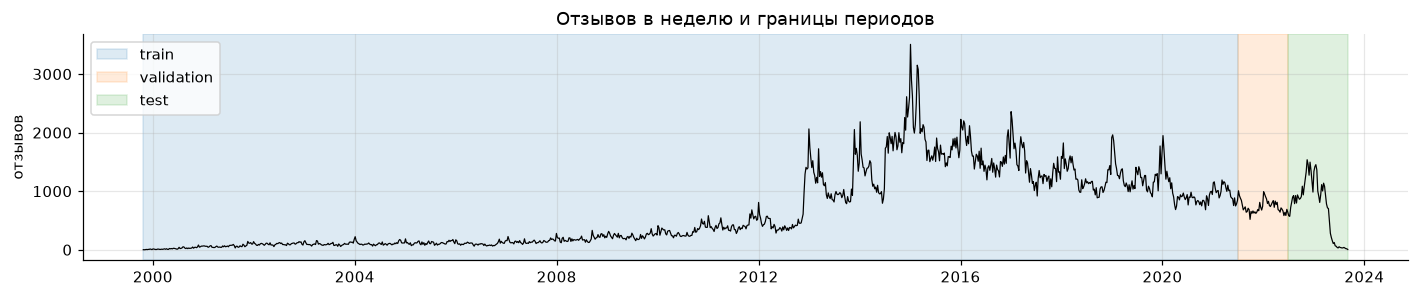

In [12]:
train_df, val_df, test_df = temporal_split(enc.interactions, SPLIT_CFG)
t_val, t_test = day_of(SPLIT_CFG.val_start), day_of(SPLIT_CFG.test_start)
fit_val = make_fit_data(train_df, t_val, enc.n_users, enc.n_items, item_features)
target_val = make_target(fit_val, val_df, SPLIT_CFG.relevance_threshold)
fit_test = make_fit_data(pd.concat([train_df, val_df]), t_test, enc.n_users, enc.n_items, item_features)
target_test = make_target(fit_test, test_df, SPLIT_CFG.relevance_threshold)

split_table = pd.DataFrame({"validation": target_val.stats, "test": target_test.stats})
split_table.loc["fit_interactions"] = [fit_val.n_interactions, fit_test.n_interactions]
split_table.loc["fit_users"] = [int(fit_val.warm_users.sum()), int(fit_test.warm_users.sum())]
display(split_table)
share = 100 * split_table.loc["relevant_interactions"] / split_table.loc["period_interactions"]
print("доля релевантных среди всех взаимодействий периода, %:", share.round(1).to_dict())

weekly = pd.Series(1, index=pd.to_datetime(enc.interactions["timestamp"], unit="ms")).resample("W").sum()
fig, ax = plt.subplots(figsize=(13, 2.8))
ax.plot(weekly.index, weekly.values, lw=0.8, c="k")
edges = [weekly.index.min(), pd.Timestamp(SPLIT_CFG.val_start), pd.Timestamp(SPLIT_CFG.test_start), weekly.index.max()]
for (lo, hi), name, color in zip(zip(edges[:-1], edges[1:]), ["train", "validation", "test"], ["C0", "C1", "C2"]):
    ax.axvspan(lo, hi, color=color, alpha=0.15, label=name)
ax.set(title="Отзывов в неделю и границы периодов", ylabel="отзывов")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

## 4. Модели: постановка и формулы

Обозначения: $X\in\{0,1\}^{|U|\times|I|}$ — матрица покупок до $t_{rec}$, $I(u)$ — товары пользователя, $U_i$ — покупатели товара $i$. Обучение, предсказание и формирование рекомендаций реализованы вручную на numpy/scipy/torch. Отбор кандидатов и исключение уже купленного выполняет общий `utils/evaluation.py`, одинаковый для всех моделей.

**0. Бейзлайны.** `Random`; `Popular`: $s_i=|U_i|$; `Popular (decay)`: $s_i=\sum_{(u,i,t)}2^{-(t_{rec}-t)/h}$ — популярность с периодом полураспада $h$.

**1. Item-based kNN.** Асимметричный косинус со сжатием (Aiolli, 2013):
$$\mathrm{sim}(i,j)=\frac{|U_i\cap U_j|}{|U_i|^{\alpha}|U_j|^{1-\alpha}+h},$$
при $\alpha=0.5$ это обычный косинус. Для каждого кандидата $i$ оставляем $k$ самых похожих товаров $N_k(i)$. Скор
$$s_{ui}=\sum_{j\in I(u)\cap N_k(i)} w_{uj}\,\mathrm{sim}(i,j),\qquad w_{uj}=2^{-(t_{rec}-t_{uj})/\tau}.$$
Вес $w_{uj}$ отдаёт приоритет недавним покупкам пользователя; при $\tau=\infty$ все покупки равноценны. Совместные покупки считаются разреженным $X^\top X$ на CPU. Нормированная матрица сходства тёплых товаров (~2 ГБ) хранится плотной на GPU, где отбор top-k и скоринг сводятся к матричным операциям.

**2. iALS** (implicit feedback; Hu, Koren, Volinsky, 2008). Предпочтение $p_{ui}=[u \text{ купил } i]$, уверенность $c_{ui}=1+\alpha p_{ui}$:
$$\min_{X,Y}\sum_{u,i}c_{ui}\,(p_{ui}-x_u^\top y_i)^2+\lambda(\|X\|_F^2+\|Y\|_F^2).$$
Шаг по пользователям при фиксированном $Y$ имеет решение в замкнутой форме
$$x_u=\big(Y^\top Y+\lambda I+\alpha\,Y_{I(u)}^\top Y_{I(u)}\big)^{-1}(1+\alpha)\,Y_{I(u)}^\top\mathbf 1,$$
шаг по товарам симметричен. Систему решаем несколькими шагами сопряжённых градиентов с тёплым стартом (Takács et al., 2011) сразу для всех пользователей. Умножение на матрицу затрагивает только наблюдаемые пары, поэтому ни одна плотная $|I|\times|I|$ матрица не строится. Скор: $s_{ui}=x_u^\top y_i$.

**3. EASE** (Steck, 2019):
$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2\quad\text{s.t.}\ \operatorname{diag}(B)=0\ \Rightarrow\ P=(X^\top X+\lambda I)^{-1},\ \ B_{ij}=-\frac{P_{ij}}{P_{jj}}\ (i\neq j).$$
Скор: $s_u=x_uB$. Обращение делается через разложение Холецкого (матрица симметрична и положительно определена) по тёплым товарам.

**4. Factorization Machine** (Rendle, 2010), обучение на BPR (Rendle et al., 2009). Событие $(u,i,t)$ — разреженный вектор $x$:
$$\hat y(x)=w_0+\sum_f w_f x_f+\sum_{f<g}\langle v_f,v_g\rangle x_f x_g,\qquad \max_\Theta\sum_{(u,i,t)}\sum_{j\sim\mathcal N(u,t)}\ln\sigma\big(\hat y(u,i,t)-\hat y(u,j,t)\big)-\lambda\|\Theta_{\text{active}}\|^2.$$
Признаки и их обоснование:

| группа | признак | зачем | доступен в момент $t$? |
|---|---|---|---|
| пользователь | user id | индивидуальный вкус | да |
| пользователь | профиль платформ: нормированная гистограмма платформ его покупок до $t_{rec}$ | пользователи лояльны платформе (п. 2.5), делит статистику между похожими пользователями | да, по прошлым покупкам |
| товар | item id, платформа, тип, store, ценовой квантиль, ESRB | содержательное сходство товаров, перенос между товарами одной платформы и издателя | да, статичный каталог |
| контекст | «возраст» товара: дни от его первого отзыва до $t$, log2-бакеты | товары продаются в основном вскоре после выхода (п. 2.6) | да, считается только по событиям **строго до** $t$ |
| контекст | свежая популярность: число отзывов за окно $[t-W, t)$, log2-бакеты | тренды, выход новых игр | да, окно открыто справа |

Признаки `average_rating`, `rating_number` и Best Sellers Rank сознательно не используются: это агрегаты, собранные в 2023 году, то есть после test. Цена тоже снята в 2023 году. Это неточность (цена на момент покупки неизвестна), но не утечка целевой переменной. Одна тонкость: у первого события товара нет прошлого, и «возраст 0» совпадал бы с позитивным примером. Поэтому для него заведён отдельный бакет «нет истории» (см. `models/fm.py`). Признаки делятся на пользовательские и товарно-контекстные, поэтому при $t=t_{rec}$ скор раскладывается как $s_{ui}=b_i+\langle s_u, s_i\rangle$ и все товары оцениваются одним матричным умножением. Негативы $j$ сэмплируются равномерно по каталогу или только среди товаров, уже существовавших в момент $t$. Режим выбирается на validation.

**5. timeSVD++** (Koren, 2009) с временными компонентами:
$$\hat r_{ui}(t)=\mu+b_u+\alpha_u\,\mathrm{dev}_u(t)+b_{u,t}+\big(b_i+b_{i,\mathrm{Bin}(t)}\big)\big(c_u+c_{u,t}\big)+q_i^\top\Big(p_u+\alpha^{p}_u\,\mathrm{dev}_u(t)+|N(u)|^{-1/2}\!\!\sum_{j\in N(u)}y_j\Big),$$
$$\mathrm{dev}_u(t)=\operatorname{sign}(t-t_u)\,|t-t_u|^{\beta}/s,\ \ \beta=0.4.$$
Здесь $t_u$ — средняя дата оценок пользователя, $t$ измеряется в днях, $s$ — стандартное отклонение $\operatorname{sign}(\cdot)|\cdot|^{\beta}$ на обучающих оценках. Без нормировки $|\mathrm{dev}|$ доходит до ~25; Koren компенсировал это шагом SGD порядка $10^{-5}$ для $\alpha$, а Adam выравнивает шаги, и дрейф переобучается первым. $\mathrm{Bin}(t)$ — один из 30 равных интервалов периода обучения, $b_{u,t}, c_{u,t}$ — параметры конкретного дня. Классическое обучение минимизирует ошибку только на наблюдаемых оценках. Такая модель учится тому, *как* пользователь оценит выбранный им товар, но не тому, *что* он выберет, и для top-N это известная проблема (Cremonesi et al., 2010; Steck, 2010). Поэтому к функции потерь добавлен член для пропущенных данных в духе AllRank (Steck, 2010). Для каждой оценки сэмплируется $n$ некупленных товаров; им приписывается низкая оценка $r_m$ с весом $w_m$:
$$\mathcal L=\sum_{(u,i,t)\in R}\big(r_{ui}-\hat r_{ui}(t)\big)^2+w_m\!\!\sum_{(u,j,t)\in S}\big(r_m-\hat r_{uj}(t)\big)^2+\text{reg}.$$
Формула предсказания не меняется, а при $n=0$ получаем классический timeSVD++. Регуляризация MAP-вида $\lambda\|\Theta\|^2$: каждый параметр штрафуется один раз, а не за каждую оценку. Поэтому редкие пользователи сжимаются к среднему сильнее частых, как в baseline predictor $b_u=\sum(r-\mu-b_i)/(\lambda+n_u)$. Обучение идёт мини-батчами из перемешанных оценок, Adam.

**Предсказание в будущем.** У Koren тестовые оценки лежат внутри периода оценок пользователя, и $\mathrm{dev}_u$ интерполирует. Здесь все прогнозы делаются после $t_{rec}$, часто через годы после $t_u$, и экстраполяция дрейфа уводила бы прогноз далеко за пределы диапазона обучения. Поэтому каждый временной параметр замораживается на последнем известном значении: дрейф пользователя берётся на его последнем дне в обучении, смещение товара — в последнем интервале, а дневные члены $b_{u,t}, c_{u,t}$ равны нулю, потому что этот день в обучении не встречался. Для ранжирования важны $(b_i+b_{i,\text{last}})\,c_u$ и $q_i^\top p_u(t_{rec})$; пользовательские смещения общие для всех товаров пользователя и на порядок не влияют.

In [13]:
pd.DataFrame(
    [{"model": name, "class": f"{cls.__module__}.{cls.__name__}", "config": cls.config_cls.__name__} for name, cls in MODEL_REGISTRY.items()]
)

,model,class,config
0,Popular,models.baselines.Popular,PopularConfig
1,Random,models.baselines.RandomRecommender,RandomConfig
2,EASE,models.ease.EASE,EASEConfig
3,FM,models.fm.FM,FMConfig
4,iALS,models.ials.IALS,IALSConfig
5,ItemKNN,models.item_knn.ItemKNN,ItemKNNConfig
6,timeSVD++,models.time_svdpp.TimeSVDpp,TimeSVDppConfig


## 5. Подбор гиперпараметров на validation

Критерий: **NDCG@10** на validation. Поиск: Optuna TPE с `seed=42`; для EASE и затухающей популярности — полная сетка. Первым испытанием каждого TPE-поиска идёт конфигурация модели по умолчанию (значения её dataclass-конфига), дальше TPE ищет лучше. Итеративные модели оцениваются после каждой эпохи (iALS — каждые 2 итерации), обучение останавливается после двух оценок без улучшения (`patience=2`). Заведомо слабые конфигурации обрываются `MedianPruner`; для timeSVD++ — не раньше 6-й эпохи, потому что он набирает качество медленнее остальных. Номер лучшей эпохи сохраняется и используется при переобучении.

| модель | пространство поиска | бюджет |
|---|---|---|
| Popular (decay) | $h\in\{7,14,30,60,120,240,480,960\}$ дней | сетка, 8 |
| ItemKNN | $k\in[10,2000]$ (лог.), $\alpha\in[0,1]$, $h\in[0,200]$, давность профиля: нет или $\tau\in[14,3650]$ дней (лог.) | TPE, 40 |
| EASE | $\lambda\in\{10,30,100,300,10^3,3\cdot10^3,10^4,3\cdot10^4\}$ | сетка, 8 |
| iALS | $d\in\{64,128,256,512\}$, $\alpha\in[0.3,300]$ (лог.), $\lambda\in[10^{-3},300]$ (лог.), итераций ≤ 30, CG-шагов 3 | TPE, 30 |
| FM | $d\in\{64,128,256\}$, lr $\in[3\cdot10^{-5},3\cdot10^{-3}]$ (лог.), $\lambda\in[10^{-7},10^{-2}]$ (лог.), негативов $\{1,2,4\}$, негативы time-aware: да/нет, окно популярности $W\in\{30,90,365\}$ дней, эпох ≤ 30 | TPE, 35 |
| timeSVD++ | $d\in\{16,32,64,128\}$, lr $\in[10^{-3},3\cdot10^{-2}]$, $\lambda_b\in[0.1,300]$, $\lambda_f,\lambda_t\in[0.1,1000]$ (все лог.), $n\in\{8,16,32\}$, $w_m\in[0.1,10]$ (лог.), $r_m\in[0,3]$, негативы time-aware: да/нет, эпох ≤ 30 | TPE, 40 |

In [14]:
VAL_SCORE = topn_score(fit_val, target_val, TUNE_CFG)


def runtime(model: str) -> dict:
    # Device is a runtime setting: it is passed to the models that support it and never saved.
    fields = MODEL_REGISTRY[model].config_cls.__dataclass_fields__
    return {"device": DEVICE} if "device" in fields else {}


def defaults(model: str, *keys: str, **extra) -> dict:
    # Default configuration of a model (its dataclass config) as the first trial of a TPE search.
    cfg = MODEL_REGISTRY[model].config_cls()
    return {**{key: getattr(cfg, key) for key in keys}, **extra}


def search(key, model, space, n_trials, fixed=None, epochs_key=None, score_fn=None, **tune_kwargs) -> dict:
    # Run (or reload) the search and return {"best_value", "params", "trials"}.
    path = RESULTS / "tuning" / f"{key}.json"
    if RUN_SEARCH or not path.exists():
        start = time.perf_counter()
        study = tune(model, space, fit_val, n_trials, TUNE_CFG, score_fn or VAL_SCORE,
                     fixed={**(fixed or {}), **runtime(model)}, **tune_kwargs)
        save_study(study, best_params(study, space, fixed, epochs_key), path)
        log.info("%s: %d trials in %.1f min", key, len(study.trials), (time.perf_counter() - start) / 60)
    saved = load_study(path)
    log.info("%s: best %.5f with %s", key, saved["best_value"], saved["params"])
    return saved


SEARCH = {}

In [15]:
POP_GRID = [7.0, 14.0, 30.0, 60.0, 120.0, 240.0, 480.0, 960.0]
SEARCH["Popular (decay)"] = search(
    "popular_decay", "Popular",
    lambda trial: {"half_life": trial.suggest_categorical("half_life", POP_GRID)},
    n_trials=len(POP_GRID), sampler=optuna.samplers.GridSampler({"half_life": POP_GRID}, seed=SEED),
)

21:58:38 utils.tuning: Popular #0: 0.01255 {'device': 'cuda', 'half_life': 14.0}
21:58:38 utils.tuning: Popular #1: 0.01531 {'device': 'cuda', 'half_life': 240.0}
21:58:39 utils.tuning: Popular #2: 0.01126 {'device': 'cuda', 'half_life': 7.0}
21:58:40 utils.tuning: Popular #3: 0.01204 {'device': 'cuda', 'half_life': 960.0}
21:58:41 utils.tuning: Popular #4: 0.01768 {'device': 'cuda', 'half_life': 30.0}
21:58:42 utils.tuning: Popular #5: 0.01632 {'device': 'cuda', 'half_life': 120.0}
21:58:42 utils.tuning: Popular #6: 0.01791 {'device': 'cuda', 'half_life': 60.0}
21:58:43 utils.tuning: Popular #7: 0.01372 {'device': 'cuda', 'half_life': 480.0}
21:58:43 utils.tuning: Popular best 0.01791 with {'half_life': 60.0}
21:58:43 experiments: popular_decay: 8 trials in 0.1 min
21:58:43 experiments: popular_decay: best 0.01791 with {'half_life': 60.0}


In [16]:
def knn_space(trial: optuna.Trial) -> dict:
    use_recency = trial.suggest_categorical("use_recency", [False, True])
    return {
        "n_neighbors": trial.suggest_int("n_neighbors", 10, 2000, log=True),
        "alpha": trial.suggest_float("alpha", 0.0, 1.0),
        "shrink": trial.suggest_float("shrink", 0.0, 200.0),
        "half_life": trial.suggest_float("half_life", 14.0, 3650.0, log=True) if use_recency else None,
    }


SEARCH["ItemKNN"] = search(
    "item_knn", "ItemKNN", knn_space, n_trials=40,
    enqueue=defaults("ItemKNN", "n_neighbors", "alpha", "shrink", use_recency=False),
)

21:58:52 utils.tuning: ItemKNN #0: 0.00892 {'device': 'cuda', 'n_neighbors': 100, 'alpha': 0.5, 'shrink': 10.0, 'half_life': None}
21:59:00 utils.tuning: ItemKNN #1: 0.01128 {'device': 'cuda', 'n_neighbors': 477, 'alpha': 0.5986584841970366, 'shrink': 31.203728088487303, 'half_life': 33.34544436102321}
21:59:08 utils.tuning: ItemKNN #2: 0.00613 {'device': 'cuda', 'n_neighbors': 237, 'alpha': 0.7080725777960455, 'shrink': 4.116898859160489, 'half_life': 3087.380149853233}
21:59:17 utils.tuning: ItemKNN #3: 0.01065 {'device': 'cuda', 'n_neighbors': 25, 'alpha': 0.18340450985343382, 'shrink': 60.84844859190754, 'half_life': None}
21:59:25 utils.tuning: ItemKNN #4: 0.00905 {'device': 'cuda', 'n_neighbors': 45, 'alpha': 0.6118528947223795, 'shrink': 27.898772130408368, 'half_life': None}
21:59:33 utils.tuning: ItemKNN #5: 0.01148 {'device': 'cuda', 'n_neighbors': 109, 'alpha': 0.7851759613930136, 'shrink': 39.93475643167195, 'half_life': 244.68266358083062}
21:59:41 utils.tuning: ItemKNN #6

In [17]:
EASE_GRID = [10.0, 30.0, 100.0, 300.0, 1000.0, 3000.0, 10000.0, 30000.0]
SEARCH["EASE"] = search(
    "ease", "EASE",
    lambda trial: {"l2": trial.suggest_categorical("l2", EASE_GRID)},
    n_trials=len(EASE_GRID), sampler=optuna.samplers.GridSampler({"l2": EASE_GRID}, seed=SEED),
)

22:05:27 utils.tuning: EASE #0: 0.01240 {'device': 'cuda', 'l2': 30.0}
22:05:36 utils.tuning: EASE #1: 0.01201 {'device': 'cuda', 'l2': 3000.0}
22:05:44 utils.tuning: EASE #2: 0.01149 {'device': 'cuda', 'l2': 10.0}
22:05:50 utils.tuning: EASE #3: 0.01220 {'device': 'cuda', 'l2': 30000.0}
22:05:58 utils.tuning: EASE #4: 0.01233 {'device': 'cuda', 'l2': 100.0}
22:06:06 utils.tuning: EASE #5: 0.01197 {'device': 'cuda', 'l2': 1000.0}
22:06:14 utils.tuning: EASE #6: 0.01211 {'device': 'cuda', 'l2': 300.0}
22:06:22 utils.tuning: EASE #7: 0.01228 {'device': 'cuda', 'l2': 10000.0}
22:06:22 utils.tuning: EASE best 0.01240 with {'l2': 30.0}
22:06:22 experiments: ease: 8 trials in 1.1 min
22:06:22 experiments: ease: best 0.01240 with {'l2': 30.0}


In [18]:
def ials_space(trial: optuna.Trial) -> dict:
    return {
        "factors": trial.suggest_categorical("factors", [64, 128, 256, 512]),
        "alpha": trial.suggest_float("alpha", 0.3, 300.0, log=True),
        "l2": trial.suggest_float("l2", 1e-3, 300.0, log=True),
    }


SEARCH["iALS"] = search(
    "ials", "iALS", ials_space, n_trials=30,
    fixed={"n_iters": 30, "cg_steps": 3, "seed": SEED}, epochs_key="n_iters",
    iterative=True, eval_every=2, pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=4),
    enqueue=defaults("iALS", "factors", "alpha", "l2"),
)

22:06:25 utils.tuning: iALS #0: 0.01054 {'n_iters': 30, 'cg_steps': 3, 'seed': 42, 'device': 'cuda', 'factors': 64, 'alpha': 10.0, 'l2': 1.0}
22:06:28 utils.tuning: iALS #1: 0.00810 {'n_iters': 30, 'cg_steps': 3, 'seed': 42, 'device': 'cuda', 'factors': 128, 'alpha': 0.8814083816110603, 'l2': 0.007151561915580051}
22:06:29 utils.tuning: iALS #2: 0.00593 {'n_iters': 30, 'cg_steps': 3, 'seed': 42, 'device': 'cuda', 'factors': 128, 'alpha': 0.3458396138469719, 'l2': 205.26450981024206}
22:06:32 utils.tuning: iALS #3: 0.00993 {'n_iters': 30, 'cg_steps': 3, 'seed': 42, 'device': 'cuda', 'factors': 64, 'alpha': 2.4538498425635007, 'l2': 0.7484358900791156}
22:06:35 utils.tuning: iALS #4: 0.00945 {'n_iters': 30, 'cg_steps': 3, 'seed': 42, 'device': 'cuda', 'factors': 256, 'alpha': 2.257122865360456, 'l2': 0.10153323854165189}
22:06:38 utils.tuning: iALS #5: 0.01184 {'n_iters': 30, 'cg_steps': 3, 'seed': 42, 'device': 'cuda', 'factors': 128, 'alpha': 17.962424731384193, 'l2': 0.001796447553958

In [19]:
def fm_space(trial: optuna.Trial) -> dict:
    return {
        "factors": trial.suggest_categorical("factors", [64, 128, 256]),
        "lr": trial.suggest_float("lr", 3e-5, 3e-3, log=True),
        "l2": trial.suggest_float("l2", 1e-7, 1e-2, log=True),
        "n_negatives": trial.suggest_categorical("n_negatives", [1, 2, 4]),
        "time_aware_negatives": trial.suggest_categorical("time_aware_negatives", [False, True]),
        "recent_window": trial.suggest_categorical("recent_window", [30.0, 90.0, 365.0]),
    }


SEARCH["FM"] = search(
    "fm", "FM", fm_space, n_trials=35,
    fixed={"n_epochs": 30, "batch_size": 4096, "seed": SEED}, epochs_key="n_epochs",
    iterative=True, pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=2),
    enqueue=defaults("FM", "factors", "lr", "l2", "n_negatives", "time_aware_negatives", "recent_window"),
)

22:08:28 utils.tuning: FM #0: 0.01739 {'n_epochs': 30, 'batch_size': 4096, 'seed': 42, 'device': 'cuda', 'factors': 64, 'lr': 0.002, 'l2': 1e-05, 'n_negatives': 1, 'time_aware_negatives': True, 'recent_window': 90.0}
22:08:52 utils.tuning: FM #1: 0.01993 {'n_epochs': 30, 'batch_size': 4096, 'seed': 42, 'device': 'cuda', 'factors': 128, 'lr': 0.00047253961499339135, 'l2': 6.026889128682512e-07, 'n_negatives': 4, 'time_aware_negatives': True, 'recent_window': 90.0}
22:09:10 utils.tuning: FM #2: 0.01214 {'n_epochs': 30, 'batch_size': 4096, 'seed': 42, 'device': 'cuda', 'factors': 64, 'lr': 0.00012178834831452911, 'l2': 4.205156450913872e-05, 'n_negatives': 4, 'time_aware_negatives': True, 'recent_window': 365.0}
22:11:32 utils.tuning: FM #3: 0.01927 {'n_epochs': 30, 'batch_size': 4096, 'seed': 42, 'device': 'cuda', 'factors': 256, 'lr': 3.715541189658275e-05, 'l2': 0.00010907475835157698, 'n_negatives': 4, 'time_aware_negatives': False, 'recent_window': 365.0}
22:12:10 utils.tuning: FM #4

In [20]:
def tsvd_space(trial: optuna.Trial) -> dict:
    return {
        "factors": trial.suggest_categorical("factors", [16, 32, 64, 128]),
        "lr": trial.suggest_float("lr", 1e-3, 3e-2, log=True),
        "l2_bias": trial.suggest_float("l2_bias", 0.1, 300.0, log=True),
        "l2_factor": trial.suggest_float("l2_factor", 0.1, 1000.0, log=True),
        "l2_time": trial.suggest_float("l2_time", 0.1, 1000.0, log=True),
        "n_negatives": trial.suggest_categorical("n_negatives", [8, 16, 32]),
        "neg_weight": trial.suggest_float("neg_weight", 0.1, 10.0, log=True),
        "neg_target": trial.suggest_float("neg_target", 0.0, 3.0),
        "time_aware_negatives": trial.suggest_categorical("time_aware_negatives", [False, True]),
    }


SEARCH["timeSVD++"] = search(
    "time_svdpp", "timeSVD++", tsvd_space, n_trials=40,
    fixed={"n_epochs": 30, "batch_size": 4096, "use_time": True, "seed": SEED}, epochs_key="n_epochs",
    iterative=True, pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=6),
    enqueue=defaults(
        "timeSVD++", "factors", "lr", "l2_bias", "l2_factor", "l2_time",
        "n_negatives", "neg_weight", "neg_target", "time_aware_negatives",
    ),
)

22:22:05 utils.tuning: timeSVD++ #0: 0.02101 {'n_epochs': 30, 'batch_size': 4096, 'use_time': True, 'seed': 42, 'device': 'cuda', 'factors': 64, 'lr': 0.003, 'l2_bias': 10.0, 'l2_factor': 10.0, 'l2_time': 10.0, 'n_negatives': 16, 'neg_weight': 1.0, 'neg_target': 0.3, 'time_aware_negatives': False}
22:23:08 utils.tuning: timeSVD++ #1: 0.01773 {'n_epochs': 30, 'batch_size': 4096, 'use_time': True, 'seed': 42, 'device': 'cuda', 'factors': 32, 'lr': 0.0017000372989211014, 'l2_bias': 0.34866781670451225, 'l2_factor': 0.17073967431528117, 'l2_time': 291.5443189153751, 'n_negatives': 16, 'neg_weight': 8.706020878304859, 'neg_target': 2.497327922401265, 'time_aware_negatives': False}
22:23:55 utils.tuning: timeSVD++ #2: 0.02024 {'n_epochs': 30, 'batch_size': 4096, 'use_time': True, 'seed': 42, 'device': 'cuda', 'factors': 64, 'lr': 0.0026926552514864714, 'l2_bias': 13.411788774467905, 'l2_factor': 0.3613894271216527, 'l2_time': 1.4742753159914666, 'n_negatives': 32, 'neg_weight': 0.25081156860

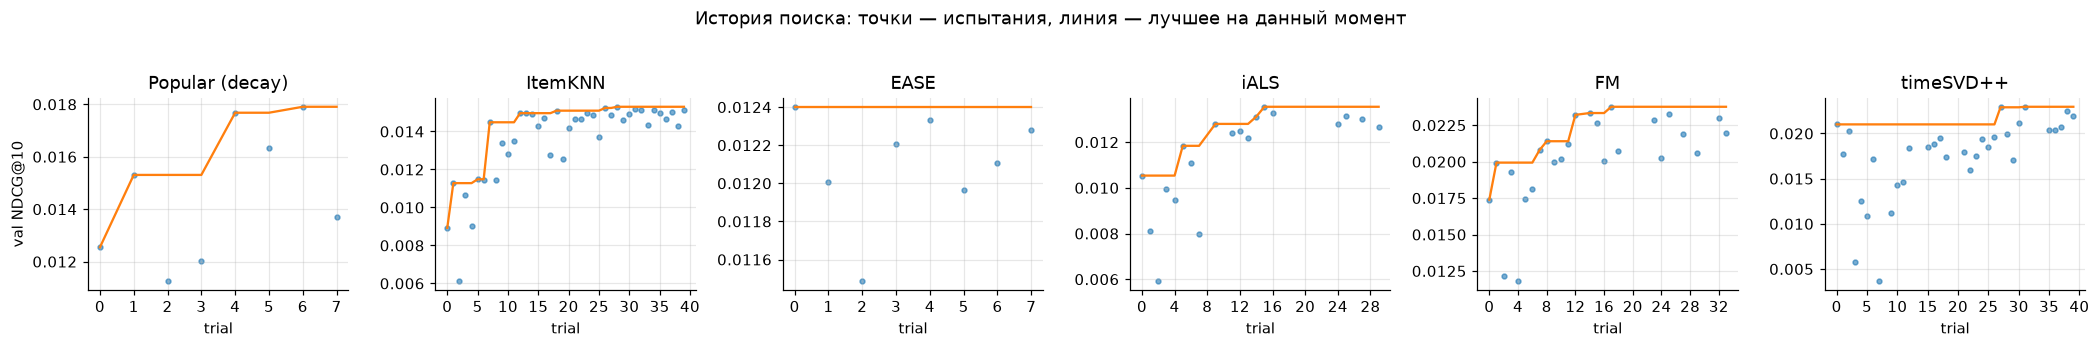

,model,val NDCG@10,trials,pruned,"search, min",selected hyperparameters
4,FM,0.02376,35,10,12.4,"{'n_epochs': 2, 'batch_size': 4096, 'seed': 42, 'factors': 128, 'lr': 0.0007435054554725872, 'l2': 0.002586633083760305, 'n_negatives': 1, 'time_aware_negatives': False, 'recent_window': 30.0}"
5,timeSVD++,0.02296,40,8,26.6,"{'n_epochs': 8, 'batch_size': 4096, 'use_time': True, 'seed': 42, 'factors': 64, 'lr': 0.0028551825424882236, 'l2_bias': 27.83692348131802, 'l2_factor': 1.8847225646914527, 'l2_time': 1.5670359027494762, 'n_negatives': 32, 'neg_weight': 0.40260857856891485, 'neg_target': 0.353232813261295, 'time_aware_negatives': False}"
0,Popular (decay),0.01791,8,0,0.0,{'half_life': 60.0}
1,ItemKNN,0.01530,40,0,6.1,"{'n_neighbors': 1123, 'alpha': 0.03162540532823872, 'shrink': 164.6756315936663, 'half_life': 59.750250313581546}"
3,iALS,0.01355,30,11,1.4,"{'n_iters': 20, 'cg_steps': 3, 'seed': 42, 'factors': 256, 'alpha': 46.347739654181396, 'l2': 114.68462726469467}"
2,EASE,0.01240,8,0,1.0,{'l2': 30.0}


In [21]:
fig, axes = plt.subplots(1, len(SEARCH), figsize=(3.2 * len(SEARCH), 3), sharey=False)
summary = []
for ax, (name, saved) in zip(axes, SEARCH.items()):
    trials = pd.DataFrame(saved["trials"])
    done = trials[trials["state"] == "COMPLETE"]
    ax.scatter(done["trial"], done["value"], s=10, alpha=0.6)
    ax.plot(done["trial"], done["value"].cummax(), c="C1")
    ax.set(title=name, xlabel="trial")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    summary.append({
        "model": name, "val NDCG@10": saved["best_value"], "trials": len(trials),
        "pruned": int((trials["state"] == "PRUNED").sum()), "search, min": trials["seconds"].fillna(0).sum() / 60,
        "selected hyperparameters": saved["params"],
    })
axes[0].set_ylabel("val NDCG@10")
plt.suptitle("История поиска: точки — испытания, линия — лучшее на данный момент", y=1.04)
plt.tight_layout(); plt.show()
search_summary = pd.DataFrame(summary).sort_values("val NDCG@10", ascending=False)
search_summary.style.format({"val NDCG@10": "{:.5f}", "search, min": "{:.1f}"})

### 5.1 Выбранные конфигурации на validation

Переобучаем каждую модель на train с выбранными параметрами (для итеративных — ровно с выбранным числом эпох) и считаем все метрики на validation. Заодно это проверка воспроизводимости: NDCG@10 должна совпасть с найденной при подборе до последнего знака.

In [22]:
FINAL = {
    "Random": ("Random", {"seed": SEED}),
    "Popular": ("Popular", {}),
    "Popular (decay)": ("Popular", SEARCH["Popular (decay)"]["params"]),
    "ItemKNN": ("ItemKNN", SEARCH["ItemKNN"]["params"]),
    "EASE": ("EASE", SEARCH["EASE"]["params"]),
    "iALS": ("iALS", SEARCH["iALS"]["params"]),
    "FM": ("FM", SEARCH["FM"]["params"]),
    "timeSVD++": ("timeSVD++", SEARCH["timeSVD++"]["params"]),
}
METRIC_COLS = [f"{m}@{K}" for m in ("ndcg", "recall", "hit_rate", "mrr", "precision", "coverage", "novelty")]


def results_table(results: dict) -> pd.DataFrame:
    rows = {name: {**res.metrics, "fit, s": sec} for name, (res, sec) in results.items()}
    return pd.DataFrame(rows).T[METRIC_COLS + ["fit, s"]]


val_results = {}
for name, (model, params) in FINAL.items():
    fitted, res, sec = fit_evaluate(model, {**params, **runtime(model)}, fit_val, target_val, TUNE_CFG)
    val_results[name] = (res, sec)
    del fitted  # drop the reference before freeing GPU memory (shared GPU)
    release_memory()
    if name in SEARCH:
        print(f"{name:16s} refit NDCG@10 = {res.metrics['ndcg@10']:.6f} | search best = {SEARCH[name]['best_value']:.6f} | equal: {np.isclose(res.metrics['ndcg@10'], SEARCH[name]['best_value'], rtol=0, atol=1e-9)}")
val_table = results_table(val_results)
val_table.to_csv(RESULTS / "val_metrics.csv")
val_table.style.format("{:.4f}").format({"fit, s": "{:.1f}", "novelty@10": "{:.2f}"}).highlight_max(axis=0, subset=METRIC_COLS[:4], color="#d4f0d4")

22:49:18 utils.tuning: Random: {'ndcg@10': 0.00035, 'recall@10': 0.00046, 'hit_rate@10': 0.00095, 'precision@10': 0.0001, 'mrr@10': 0.00041, 'coverage@10': 0.98278, 'novelty@10': 12.65364} (fit 0.0s)
22:49:19 utils.tuning: Popular: {'ndcg@10': 0.00708, 'recall@10': 0.01114, 'hit_rate@10': 0.01962, 'precision@10': 0.00199, 'mrr@10': 0.0083, 'coverage@10': 0.00075, 'novelty@10': 5.60641} (fit 0.0s)
22:49:20 utils.tuning: Popular: {'ndcg@10': 0.01791, 'recall@10': 0.03261, 'hit_rate@10': 0.05451, 'precision@10': 0.00574, 'mrr@10': 0.01928, 'coverage@10': 0.00083, 'novelty@10': 8.19997} (fit 0.0s)


Popular (decay)  refit NDCG@10 = 0.017906 | search best = 0.017906 | equal: True
22:49:28 utils.tuning: ItemKNN: {'ndcg@10': 0.0153, 'recall@10': 0.02523, 'hit_rate@10': 0.04147, 'precision@10': 0.00467, 'mrr@10': 0.01594, 'coverage@10': 0.47995, 'novelty@10': 8.92583} (fit 6.7s)


ItemKNN          refit NDCG@10 = 0.015301 | search best = 0.015301 | equal: True
22:49:35 utils.tuning: EASE: {'ndcg@10': 0.0124, 'recall@10': 0.02004, 'hit_rate@10': 0.03394, 'precision@10': 0.00386, 'mrr@10': 0.01365, 'coverage@10': 0.36972, 'novelty@10': 8.606} (fit 1.8s)


EASE             refit NDCG@10 = 0.012402 | search best = 0.012402 | equal: True
22:49:53 utils.tuning: iALS: {'ndcg@10': 0.01355, 'recall@10': 0.02299, 'hit_rate@10': 0.0385, 'precision@10': 0.00438, 'mrr@10': 0.01454, 'coverage@10': 0.16102, 'novelty@10': 8.58614} (fit 2.6s)


iALS             refit NDCG@10 = 0.013547 | search best = 0.013547 | equal: True
22:50:06 utils.tuning: FM: {'ndcg@10': 0.02376, 'recall@10': 0.03866, 'hit_rate@10': 0.06098, 'precision@10': 0.00638, 'mrr@10': 0.02564, 'coverage@10': 0.00368, 'novelty@10': 8.95322} (fit 7.8s)


FM               refit NDCG@10 = 0.023764 | search best = 0.023764 | equal: True
22:51:04 utils.tuning: timeSVD++: {'ndcg@10': 0.02296, 'recall@10': 0.03855, 'hit_rate@10': 0.06204, 'precision@10': 0.00663, 'mrr@10': 0.02408, 'coverage@10': 0.05259, 'novelty@10': 8.44767} (fit 51.4s)


timeSVD++        refit NDCG@10 = 0.022955 | search best = 0.022955 | equal: True


,ndcg@10,recall@10,hit_rate@10,mrr@10,precision@10,coverage@10,novelty@10,"fit, s"
Random,0.000349,0.000457,0.000955,0.000415,0.000095,0.982776,12.65,0.0
Popular,0.007080,0.011142,0.019620,0.008296,0.001994,0.000745,5.61,0.0
Popular (decay),0.017906,0.032612,0.054513,0.019280,0.005738,0.000833,8.20,0.0
ItemKNN,0.015301,0.025234,0.041468,0.015942,0.004666,0.479949,8.93,6.7
EASE,0.012402,0.020037,0.033938,0.013648,0.003860,0.369724,8.61,1.8
iALS,0.013547,0.022994,0.038498,0.014542,0.004380,0.161020,8.59,2.6
FM,0.023764,0.038657,0.060982,0.025644,0.006385,0.003681,8.95,7.8
timeSVD++,0.022955,0.038551,0.062043,0.024078,0.006628,0.052592,8.45,51.4


## 6. Финальное сравнение на test

Все модели переобучаются на train + validation (до `2022-07-01`) с параметрами из раздела 5 и один раз оцениваются на test. Пользователи, кандидаты, исключения и критерий релевантности у всех моделей одинаковые.

In [23]:
test_results, test_models = {}, {}
for name, (model, params) in FINAL.items():
    fitted, res, sec = fit_evaluate(model, {**params, **runtime(model)}, fit_test, target_test, TUNE_CFG)
    test_results[name] = (res, sec)
    if name in ("FM", "timeSVD++"):
        test_models[name] = fitted  # kept for interpretation below
    del fitted
    release_memory()
test_table = results_table(test_results)
test_table.to_csv(RESULTS / "test_metrics.csv")
test_table.style.format("{:.4f}").format({"fit, s": "{:.1f}", "novelty@10": "{:.2f}"}).highlight_max(axis=0, subset=METRIC_COLS[:4], color="#d4f0d4")

22:51:31 utils.tuning: Random: {'ndcg@10': 0.0003, 'recall@10': 0.00043, 'hit_rate@10': 0.00074, 'precision@10': 7e-05, 'mrr@10': 0.00029, 'coverage@10': 0.96544, 'novelty@10': 12.63835} (fit 0.0s)
22:51:35 utils.tuning: Popular: {'ndcg@10': 0.0039, 'recall@10': 0.00659, 'hit_rate@10': 0.01331, 'precision@10': 0.00137, 'mrr@10': 0.00443, 'coverage@10': 0.00075, 'novelty@10': 5.60918} (fit 0.0s)
22:51:36 utils.tuning: Popular: {'ndcg@10': 0.0191, 'recall@10': 0.03724, 'hit_rate@10': 0.06569, 'precision@10': 0.00696, 'mrr@10': 0.01837, 'coverage@10': 0.00062, 'novelty@10': 8.77516} (fit 0.0s)
22:51:52 utils.tuning: ItemKNN: {'ndcg@10': 0.01293, 'recall@10': 0.02248, 'hit_rate@10': 0.03808, 'precision@10': 0.00426, 'mrr@10': 0.01417, 'coverage@10': 0.44198, 'novelty@10': 9.23808} (fit 7.0s)
22:52:04 utils.tuning: EASE: {'ndcg@10': 0.01134, 'recall@10': 0.01814, 'hit_rate@10': 0.03266, 'precision@10': 0.00361, 'mrr@10': 0.01313, 'coverage@10': 0.34972, 'novelty@10': 8.7508} (fit 3.9s)
22:5

,ndcg@10,recall@10,hit_rate@10,mrr@10,precision@10,coverage@10,novelty@10,"fit, s"
Random,0.000302,0.000426,0.000739,0.000295,0.000074,0.965444,12.64,0.0
Popular,0.003896,0.006595,0.013310,0.004427,0.001368,0.000749,5.61,0.0
Popular (decay),0.019097,0.037235,0.065689,0.018369,0.006963,0.000625,8.78,0.0
ItemKNN,0.012930,0.022484,0.038082,0.014172,0.004264,0.441983,9.24,7.0
EASE,0.011342,0.018138,0.032660,0.013126,0.003611,0.349723,8.75,3.9
iALS,0.013738,0.023230,0.040917,0.015084,0.004523,0.152005,8.68,2.0
FM,0.018858,0.033853,0.057062,0.019130,0.006051,0.003414,9.87,9.5
timeSVD++,0.022008,0.042015,0.070126,0.021273,0.007579,0.046505,8.82,55.9


,NDCG@10,NDCG 95% CI,Recall@10,Recall 95% CI,Δ NDCG vs timeSVD++,Δ 95% CI,p-value
model,,,,,,,
timeSVD++,0.0220,"[0.0201, 0.0241]",0.0420,"[0.0383, 0.0461]",nan,nan,nan
Popular (decay),0.0191,"[0.0171, 0.0211]",0.0372,"[0.0334, 0.0409]",0.0029,"[0.0010, 0.0048]",0.0020
FM,0.0189,"[0.0170, 0.0209]",0.0339,"[0.0303, 0.0373]",0.0031,"[0.0009, 0.0052]",0.0060
iALS,0.0137,"[0.0120, 0.0155]",0.0232,"[0.0204, 0.0261]",0.0083,"[0.0061, 0.0106]",0.0000
ItemKNN,0.0129,"[0.0114, 0.0146]",0.0225,"[0.0198, 0.0254]",0.0091,"[0.0068, 0.0113]",0.0000
EASE,0.0113,"[0.0098, 0.0129]",0.0181,"[0.0158, 0.0206]",0.0107,"[0.0085, 0.0129]",0.0000
Popular,0.0039,"[0.0030, 0.0048]",0.0066,"[0.0051, 0.0081]",0.0181,"[0.0161, 0.0204]",0.0000
Random,0.0003,"[0.0001, 0.0006]",0.0004,"[0.0001, 0.0008]",0.0217,"[0.0197, 0.0239]",0.0000


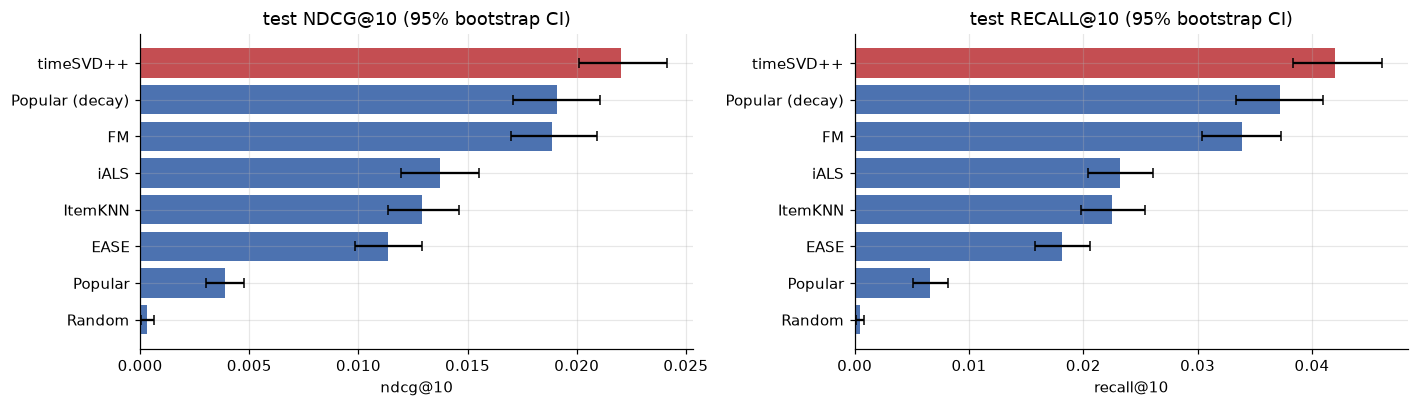

In [24]:
best_name = test_table["ndcg@10"].idxmax()
rows = []
for name, (res, _) in test_results.items():
    ndcg = bootstrap_ci(res.per_user["ndcg"], n_boot=1000, seed=SEED)
    recall = bootstrap_ci(res.per_user["recall"], n_boot=1000, seed=SEED)
    row = {"model": name, "NDCG@10": ndcg[0], "NDCG 95% CI": f"[{ndcg[1]:.4f}, {ndcg[2]:.4f}]",
           "Recall@10": recall[0], "Recall 95% CI": f"[{recall[1]:.4f}, {recall[2]:.4f}]"}
    if name != best_name:
        diff = paired_bootstrap(test_results[best_name][0].per_user["ndcg"], res.per_user["ndcg"], n_boot=1000, seed=SEED)
        row.update({f"Δ NDCG vs {best_name}": diff["diff"], "Δ 95% CI": f"[{diff['lo']:.4f}, {diff['hi']:.4f}]", "p-value": diff["p_value"]})
    rows.append(row)
ci_table = pd.DataFrame(rows).set_index("model").sort_values("NDCG@10", ascending=False)
ci_table.to_csv(RESULTS / "test_bootstrap.csv")
display(ci_table.style.format(precision=4))

order = ci_table.index[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, metric in zip(axes, ["ndcg", "recall"]):
    stats = [bootstrap_ci(test_results[n][0].per_user[metric], n_boot=1000, seed=SEED) for n in order]
    means = np.array([s[0] for s in stats]); err = np.array([[s[0] - s[1], s[2] - s[0]] for s in stats]).T
    ax.barh(order, means, xerr=err, color=["#C44E52" if n == best_name else "#4C72B0" for n in order], capsize=3)
    ax.set(title=f"test {metric.upper()}@10 (95% bootstrap CI)", xlabel=f"{metric}@10")
plt.tight_layout(); plt.show()

### 6.1 Итоговая таблица: метрики на test и выбранные гиперпараметры

In [25]:
final_table = test_table[["ndcg@10", "recall@10", "hit_rate@10", "mrr@10", "coverage@10", "novelty@10", "fit, s"]].copy()
final_table.insert(0, "val ndcg@10", val_table["ndcg@10"])
final_table["hyperparameters"] = [json.dumps(FINAL[name][1], ensure_ascii=False) for name in final_table.index]
final_table = final_table.sort_values("ndcg@10", ascending=False)
final_table.to_csv(RESULTS / "final_table.csv")
final_table.style.format(precision=4).format({"fit, s": "{:.1f}", "novelty@10": "{:.2f}"})

,val ndcg@10,ndcg@10,recall@10,hit_rate@10,mrr@10,coverage@10,novelty@10,"fit, s",hyperparameters
timeSVD++,0.022955,0.022008,0.042015,0.070126,0.021273,0.046505,8.82,55.9,"{""n_epochs"": 8, ""batch_size"": 4096, ""use_time"": true, ""seed"": 42, ""factors"": 64, ""lr"": 0.0028551825424882236, ""l2_bias"": 27.83692348131802, ""l2_factor"": 1.8847225646914527, ""l2_time"": 1.5670359027494762, ""n_negatives"": 32, ""neg_weight"": 0.40260857856891485, ""neg_target"": 0.353232813261295, ""time_aware_negatives"": false}"
Popular (decay),0.017906,0.019097,0.037235,0.065689,0.018369,0.000625,8.78,0.0,"{""half_life"": 60.0}"
FM,0.023764,0.018858,0.033853,0.057062,0.019130,0.003414,9.87,9.5,"{""n_epochs"": 2, ""batch_size"": 4096, ""seed"": 42, ""factors"": 128, ""lr"": 0.0007435054554725872, ""l2"": 0.002586633083760305, ""n_negatives"": 1, ""time_aware_negatives"": false, ""recent_window"": 30.0}"
iALS,0.013547,0.013738,0.023230,0.040917,0.015084,0.152005,8.68,2.0,"{""n_iters"": 20, ""cg_steps"": 3, ""seed"": 42, ""factors"": 256, ""alpha"": 46.347739654181396, ""l2"": 114.68462726469467}"
ItemKNN,0.015301,0.012930,0.022484,0.038082,0.014172,0.441983,9.24,7.0,"{""n_neighbors"": 1123, ""alpha"": 0.03162540532823872, ""shrink"": 164.6756315936663, ""half_life"": 59.750250313581546}"
EASE,0.012402,0.011342,0.018138,0.032660,0.013126,0.349723,8.75,3.9,"{""l2"": 30.0}"
Popular,0.007080,0.003896,0.006595,0.013310,0.004427,0.000749,5.61,0.0,{}
Random,0.000349,0.000302,0.000426,0.000739,0.000295,0.965444,12.64,0.0,"{""seed"": 42}"


## 7. Анализ

### 7.1 Влияние метаданных и контекста в FM (абляция)

Берём выбранные для FM гиперпараметры и по очереди добавляем группы признаков. Для каждого варианта режим сэмплирования негативов (равномерный или time-aware) и число эпох заново выбираются на validation по тому же критерию. Затем вариант переобучается на train + validation и оценивается на test.

In [26]:
def select_on_val(model: str, params: dict, options: list, max_epochs: int = 30) -> tuple:
    # Pick the option and the epoch count by validation NDCG@10; returns (params, val_value).
    best = (-np.inf, None, None)
    for option in options:
        monitor = EpochMonitor(VAL_SCORE, patience=TUNE_CFG.patience)
        build_model(model, **{**params, **option, "n_epochs": max_epochs, **runtime(model)}).fit(fit_val, callback=monitor)
        release_memory()
        if monitor.best_value > best[0]:
            best = (monitor.best_value, option, monitor.best_epoch)
    value, option, epochs = best
    return {**params, **option, "n_epochs": epochs}, value


FM_BASE = {k: v for k, v in SEARCH["FM"]["params"].items() if k not in ("n_epochs", "time_aware_negatives")}
NO_FEATURES = dict(use_item_meta=False, use_user_profile=False, use_item_age=False, use_recent_pop=False)
FM_VARIANTS = {
    "FM: только ID (≈ BPR-MF)": NO_FEATURES,
    "+ метаданные товара": {**NO_FEATURES, "use_item_meta": True},
    "+ профиль платформ пользователя": {**NO_FEATURES, "use_item_meta": True, "use_user_profile": True},
    "+ свежая популярность (контекст)": {**NO_FEATURES, "use_item_meta": True, "use_user_profile": True, "use_recent_pop": True},
    "+ возраст товара (полная FM)": {},
}
SAMPLERS = [{"time_aware_negatives": False}, {"time_aware_negatives": True}]
fm_ablation = []
for variant, flags in FM_VARIANTS.items():
    params, val_value = select_on_val("FM", {**FM_BASE, **flags}, SAMPLERS)
    fitted, res, sec = fit_evaluate("FM", {**params, **runtime("FM")}, fit_test, target_test, TUNE_CFG)
    del fitted
    release_memory()
    fm_ablation.append({"variant": variant, "val NDCG@10": val_value, **{f"test {m}": res.metrics[m] for m in METRIC_COLS[:2] + ["coverage@10", "novelty@10"]},
                        "time-aware negatives": params["time_aware_negatives"], "epochs": params["n_epochs"]})
fm_ablation = pd.DataFrame(fm_ablation).set_index("variant")
fm_ablation.to_csv(RESULTS / "ablation_fm.csv")
fm_ablation.style.format(precision=4).format({"test novelty@10": "{:.2f}"})

22:56:43 utils.tuning: FM: {'ndcg@10': 0.02171, 'recall@10': 0.03474, 'hit_rate@10': 0.06039, 'precision@10': 0.00637, 'mrr@10': 0.0246, 'coverage@10': 0.04151, 'novelty@10': 8.99456} (fit 41.8s)
22:58:16 utils.tuning: FM: {'ndcg@10': 0.0163, 'recall@10': 0.03013, 'hit_rate@10': 0.05102, 'precision@10': 0.00545, 'mrr@10': 0.0166, 'coverage@10': 0.0025, 'novelty@10': 9.80638} (fit 15.0s)
22:59:04 utils.tuning: FM: {'ndcg@10': 0.01858, 'recall@10': 0.03156, 'hit_rate@10': 0.05275, 'precision@10': 0.00563, 'mrr@10': 0.01962, 'coverage@10': 0.00516, 'novelty@10': 9.50103} (fit 9.9s)
22:59:42 utils.tuning: FM: {'ndcg@10': 0.01881, 'recall@10': 0.03269, 'hit_rate@10': 0.05657, 'precision@10': 0.00589, 'mrr@10': 0.01996, 'coverage@10': 0.00329, 'novelty@10': 10.25326} (fit 7.5s)
23:00:30 utils.tuning: FM: {'ndcg@10': 0.01886, 'recall@10': 0.03385, 'hit_rate@10': 0.05706, 'precision@10': 0.00605, 'mrr@10': 0.01913, 'coverage@10': 0.00341, 'novelty@10': 9.86735} (fit 8.1s)


,val NDCG@10,test ndcg@10,test recall@10,test coverage@10,test novelty@10,time-aware negatives,epochs
variant,,,,,,,
FM: только ID (≈ BPR-MF),0.018062,0.021709,0.034743,0.041509,8.99,True,12
+ метаданные товара,0.022261,0.016302,0.030126,0.002498,9.81,True,4
+ профиль платформ пользователя,0.020755,0.018578,0.031561,0.005163,9.50,True,3
+ свежая популярность (контекст),0.023569,0.018807,0.032692,0.003289,10.25,True,2
+ возраст товара (полная FM),0.023764,0.018858,0.033853,0.003414,9.87,False,2


### 7.2 timeSVD++: временные компоненты и цель обучения

Сначала проверим timeSVD++ на задаче, для которой он создавался, — **предсказании оценок**. Классическая постановка ($n=0$) подбирается по RMSE на оценках validation (TPE, 20 испытаний); учитываются все оценки тёплых пользователей и товаров. Для сравнения берём глобальное среднее, baseline predictor $\mu+b_u+b_i$ (регуляризованные смещения, Koren 2008, $\lambda_u=10$, $\lambda_i=25$) и SVD++ без временных членов с теми же гиперпараметрами.

In [27]:
known = (fit_val.user_counts[val_df["user"].to_numpy()] > 0) & (fit_val.item_counts[val_df["item"].to_numpy()] > 0)
val_known = val_df[known]
u_k, i_k, d_k, r_k = (val_known[c].to_numpy() for c in ("user", "item", "day", "rating"))


def neg_rmse(model) -> float:
    return -float(np.sqrt(np.mean((model.predict(u_k, i_k, d_k) - r_k) ** 2)))


def bias_baseline(fit, lam_u: float = 10.0, lam_i: float = 25.0, n_iter: int = 10):
    mu, b_u, b_i = fit.ratings.mean(), np.zeros(fit.n_users), np.zeros(fit.n_items)
    for _ in range(n_iter):
        b_i = np.bincount(fit.items, fit.ratings - mu - b_u[fit.users], fit.n_items) / (lam_i + fit.item_counts)
        b_u = np.bincount(fit.users, fit.ratings - mu - b_i[fit.items], fit.n_users) / (lam_u + fit.user_counts)
    return mu, b_u, b_i


def rmse_space(trial: optuna.Trial) -> dict:
    return {
        "factors": trial.suggest_categorical("factors", [16, 32, 64]),
        "lr": trial.suggest_float("lr", 1e-3, 3e-2, log=True),
        "l2_bias": trial.suggest_float("l2_bias", 1.0, 300.0, log=True),
        "l2_factor": trial.suggest_float("l2_factor", 1.0, 1000.0, log=True),
        "l2_time": trial.suggest_float("l2_time", 1.0, 1000.0, log=True),
    }


rmse_search = search(
    "time_svdpp_rmse", "timeSVD++", rmse_space, n_trials=20, score_fn=neg_rmse,
    fixed={"n_epochs": 30, "batch_size": 4096, "n_negatives": 0, "use_time": True, "seed": SEED},
    epochs_key="n_epochs", iterative=True, enqueue=defaults("timeSVD++", "lr", "l2_bias", "l2_factor", "l2_time", factors=32),
)
mu, b_u, b_i = bias_baseline(fit_val)
rows = [
    {"model": "global mean", "val RMSE": float(np.sqrt(np.mean((fit_val.ratings.mean() - r_k) ** 2))), "val NDCG@10": np.nan},
    {"model": "baseline μ + b_u + b_i", "val RMSE": float(np.sqrt(np.mean((mu + b_u[u_k] + b_i[i_k] - r_k) ** 2))), "val NDCG@10": np.nan},
]
for label, use_time in [("SVD++ (MSE)", False), ("timeSVD++ (MSE)", True)]:
    base = {**rmse_search["params"], "use_time": use_time}
    monitor = EpochMonitor(neg_rmse, patience=TUNE_CFG.patience)
    build_model("timeSVD++", **{**base, "n_epochs": 30, **runtime("timeSVD++")}).fit(fit_val, callback=monitor)
    model = build_model("timeSVD++", **{**base, "n_epochs": monitor.best_epoch, **runtime("timeSVD++")}).fit(fit_val)
    rows.append({"model": label, "val RMSE": -neg_rmse(model), "val NDCG@10": VAL_SCORE(model), "epochs": monitor.best_epoch})
    del model
    release_memory()
rmse_table = pd.DataFrame(rows).set_index("model")
rmse_table.to_csv(RESULTS / "rmse_validation.csv")
rmse_table.style.format({"val RMSE": "{:.4f}", "val NDCG@10": "{:.4f}", "epochs": "{:.0f}"})

/home/meowser52/recsys-hw1/models/time_svdpp.py:168: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  return torch.from_numpy(np.ascontiguousarray(array)).to(self.device)


23:00:54 utils.tuning: timeSVD++ #0: -1.29783 {'n_epochs': 30, 'batch_size': 4096, 'n_negatives': 0, 'use_time': True, 'seed': 42, 'device': 'cuda', 'factors': 32, 'lr': 0.003, 'l2_bias': 10.0, 'l2_factor': 10.0, 'l2_time': 10.0}
23:01:06 utils.tuning: timeSVD++ #1: -1.32000 {'n_epochs': 30, 'batch_size': 4096, 'n_negatives': 0, 'use_time': True, 'seed': 42, 'device': 'cuda', 'factors': 32, 'lr': 0.007661100707771362, 'l2_bias': 2.4348773534554593, 'l2_factor': 2.937538457632828, 'l2_time': 1.4936568554617629}
23:02:10 utils.tuning: timeSVD++ #2: -1.33648 {'n_epochs': 30, 'batch_size': 4096, 'n_negatives': 0, 'use_time': True, 'seed': 42, 'device': 'cuda', 'factors': 16, 'lr': 0.0010725209743171994, 'l2_bias': 252.68782075084553, 'l2_factor': 314.2880890840108, 'l2_time': 4.335281794951563}
23:02:24 utils.tuning: timeSVD++ #3: -1.30366 {'n_epochs': 30, 'batch_size': 4096, 'n_negatives': 0, 'use_time': True, 'seed': 42, 'device': 'cuda', 'factors': 64, 'lr': 0.0059583893500689536, 'l2_b

,val RMSE,val NDCG@10,epochs
model,,,
global mean,1.3733,nan,nan
baseline μ + b_u + b_i,1.2813,nan,nan
SVD++ (MSE),1.2706,0.0007,8
timeSVD++ (MSE),1.2691,0.0002,12


Теперь **top-N**. Сравниваем выбранный timeSVD++ (с членом для пропущенных данных) с вариантами, в которых выключены временные компоненты (SVD++) и/или член для пропущенных данных (обучение только на наблюдаемых оценках). Остальные гиперпараметры совпадают с выбранными; число эпох каждому варианту подбирается на validation заново.

In [28]:
TSVD_BASE = {k: v for k, v in SEARCH["timeSVD++"]["params"].items() if k != "n_epochs"}
TSVD_VARIANTS = {
    "timeSVD++ (выбранный)": {},
    "SVD++: без временных членов": {"use_time": False},
    "timeSVD++: только наблюдаемые оценки (n=0)": {"n_negatives": 0},
    "SVD++: только наблюдаемые оценки": {"use_time": False, "n_negatives": 0},
}
tsvd_ablation = []
for variant, change in TSVD_VARIANTS.items():
    params, val_value = select_on_val("timeSVD++", {**TSVD_BASE, **change}, [{}])
    fitted, res, sec = fit_evaluate("timeSVD++", {**params, **runtime("timeSVD++")}, fit_test, target_test, TUNE_CFG)
    del fitted
    release_memory()
    tsvd_ablation.append({"variant": variant, "val NDCG@10": val_value, **{f"test {m}": res.metrics[m] for m in METRIC_COLS[:2] + ["coverage@10", "novelty@10"]}, "epochs": params["n_epochs"]})
tsvd_ablation = pd.DataFrame(tsvd_ablation).set_index("variant")
tsvd_ablation.to_csv(RESULTS / "ablation_time_svdpp.csv")
tsvd_ablation.style.format(precision=4).format({"test novelty@10": "{:.2f}"})

23:17:15 utils.tuning: timeSVD++: {'ndcg@10': 0.02201, 'recall@10': 0.04202, 'hit_rate@10': 0.07013, 'precision@10': 0.00758, 'mrr@10': 0.02127, 'coverage@10': 0.0465, 'novelty@10': 8.82472} (fit 52.1s)
23:17:33 utils.tuning: timeSVD++: {'ndcg@10': 0.00495, 'recall@10': 0.00746, 'hit_rate@10': 0.01565, 'precision@10': 0.0016, 'mrr@10': 0.00608, 'coverage@10': 0.00167, 'novelty@10': 5.62777} (fit 4.3s)
23:18:07 utils.tuning: timeSVD++: {'ndcg@10': 0.00336, 'recall@10': 0.00534, 'hit_rate@10': 0.00974, 'precision@10': 0.00097, 'mrr@10': 0.00379, 'coverage@10': 0.02627, 'novelty@10': 10.78844} (fit 4.0s)
23:18:26 utils.tuning: timeSVD++: {'ndcg@10': 0.00165, 'recall@10': 0.00288, 'hit_rate@10': 0.00592, 'precision@10': 0.00059, 'mrr@10': 0.00203, 'coverage@10': 0.15504, 'novelty@10': 9.30618} (fit 5.8s)


,val NDCG@10,test ndcg@10,test recall@10,test coverage@10,test novelty@10,epochs
variant,,,,,,
timeSVD++ (выбранный),0.022955,0.022008,0.042015,0.046505,8.82,8
SVD++: без временных членов,0.008682,0.004949,0.007461,0.001665,5.63,1
timeSVD++: только наблюдаемые оценки (n=0),0.003195,0.003361,0.005338,0.026271,10.79,1
SVD++: только наблюдаемые оценки,0.002487,0.001646,0.002877,0.155044,9.31,3


Что выучили временные компоненты финальной модели (обучена до `2022-07-01`)? Слева показана траектория смещения товара $b_i+b_{i,\mathrm{Bin}(t)}$ по 30 временным интервалам для самых покупаемых товаров последних лет. Справа — распределение дрейфа смещения пользователя $\alpha_u$.

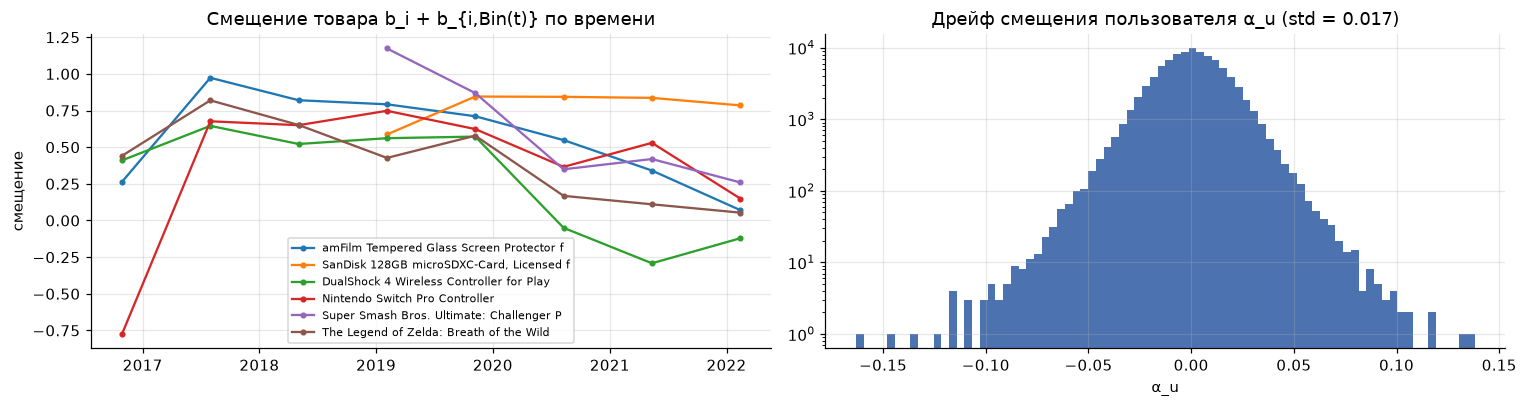

In [29]:
tsvd = test_models["timeSVD++"]
net = tsvd.net
n_bins = tsvd.cfg.n_bins
bin_mid = pd.to_datetime((tsvd.t0 + (np.arange(n_bins) + 0.5) * (tsvd.t_rec - tsvd.t0) / n_bins) * MS_PER_DAY, unit="ms")
recent = enc.interactions[enc.interactions["day"] >= day_of("2019-01-01")]
top_items = recent[recent["day"] < t_test]["item"].value_counts().index[:6]
with torch.no_grad():
    b_i = net.b_i.weight.squeeze(-1).cpu().numpy()
    b_bin = net.b_ibin.weight.squeeze(-1).cpu().numpy().reshape(-1, n_bins)
    alpha_u = net.a_u.weight.squeeze(-1).cpu().numpy()
first_bins = tsvd._bin(item_first_day(fit_test.items, fit_test.days, fit_test.n_items)[top_items])
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for item, first_bin in zip(top_items, first_bins, strict=True):
    traj = b_i[item] + b_bin[item]
    axes[0].plot(bin_mid[first_bin:], traj[first_bin:], marker="o", ms=3, label=enc.items.loc[item, "title"][:40])
axes[0].set(title="Смещение товара b_i + b_{i,Bin(t)} по времени", ylabel="смещение")
axes[0].legend(fontsize=7)
warm = fit_test.user_counts > 0
axes[1].hist(alpha_u[warm], bins=80, color="#4C72B0")
axes[1].set(title=f"Дрейф смещения пользователя α_u (std = {alpha_u[warm].std():.3f})", xlabel="α_u", yscale="log")
plt.tight_layout(); plt.show()

### 7.3 Что выучила FM: совместимость платформ

Взаимодействие признака «профиль пользователя: платформа $p$» с признаком «платформа товара $q$» вносит в скор $\langle v^{\text{user}}_p, v^{\text{item}}_q\rangle$. Матрица ниже — эти скалярные произведения для самых массовых платформ. Строки — платформа в истории пользователя, столбцы — платформа товара.

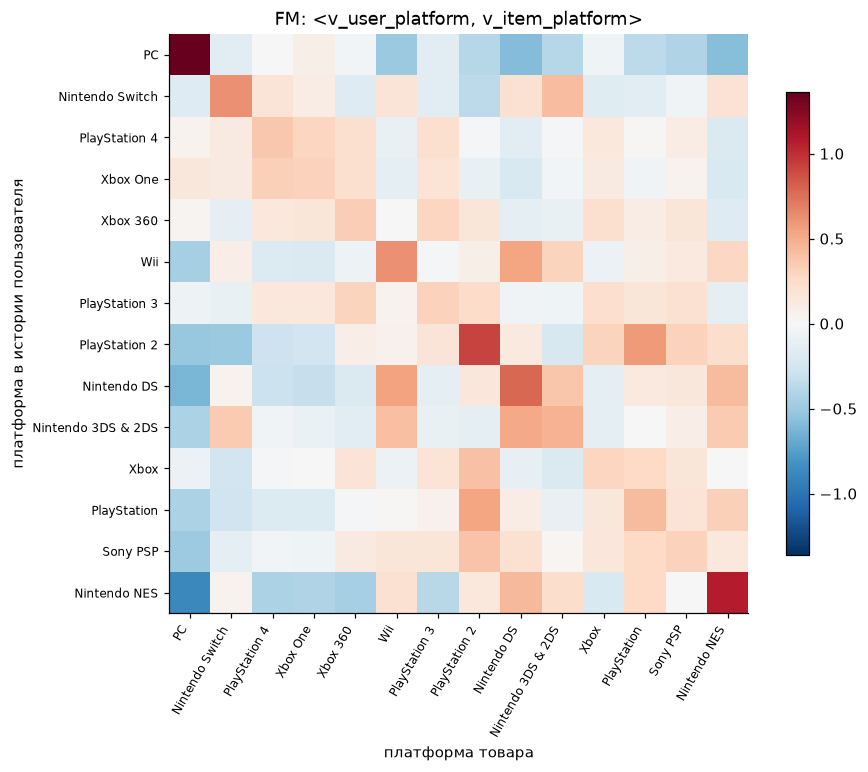

In [30]:
fm = test_models["FM"]
if fm.cfg.use_user_profile and fm.cfg.use_item_meta:
    vocab = item_features.vocab["platform"]
    counts = pd.Series(item_features.codes["platform"]).value_counts()
    top = [c for c in counts.index if vocab[c] not in ("unknown", "other")][:14]
    with torch.no_grad():
        emb = fm.net.embed.weight.cpu().numpy()
    user_v = emb[fm.space.offsets["user_platform"] + np.array(top)]
    item_v = emb[fm.space.offsets["item_platform"] + np.array(top)]
    affinity = pd.DataFrame(user_v @ item_v.T, index=[vocab[c] for c in top], columns=[vocab[c] for c in top])
    fig, ax = plt.subplots(figsize=(8.5, 7))
    lim = np.abs(affinity.to_numpy()).max()
    im = ax.imshow(affinity, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_xticks(range(len(top)), affinity.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(top)), affinity.index, fontsize=8)
    ax.set(xlabel="платформа товара", ylabel="платформа в истории пользователя", title="FM: <v_user_platform, v_item_platform>")
    ax.grid(False); plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

### 7.4 Качество по группам активности пользователей и «возраст» рекомендаций

In [31]:
activity = fit_test.user_counts[target_test.users]
groups = pd.cut(activity, [0, 4, 9, 19, np.inf], labels=["1-4", "5-9", "10-19", "20+"])
by_group = pd.DataFrame({name: pd.Series(res.per_user["ndcg"]).groupby(groups, observed=False).mean() for name, (res, _) in test_results.items()}).T
by_group.columns = [f"{g} (n={int((groups == g).sum())})" for g in by_group.columns]
display(by_group.loc[final_table.index].style.format("{:.4f}").background_gradient(axis=0, cmap="Greens"))

first_seen = item_first_day(fit_test.items, fit_test.days, fit_test.n_items)
rel = target_test.relevant[target_test.users].tocoo()
age_rows = [{"list": "релевантные товары test", "median age, days": np.median(t_test - first_seen[rel.col]),
             "share age < 1y": np.mean(t_test - first_seen[rel.col] < 365), "median train count": np.median(fit_test.item_counts[rel.col])}]
for name, (res, _) in test_results.items():
    rec = res.topk.ravel()
    age_rows.append({"list": name, "median age, days": np.median(t_test - first_seen[rec]),
                     "share age < 1y": np.mean(t_test - first_seen[rec] < 365), "median train count": np.median(fit_test.item_counts[rec])})
age_table = pd.DataFrame(age_rows).set_index("list")
age_table.to_csv(RESULTS / "recommendation_age.csv")
age_table.style.format({"median age, days": "{:.0f}", "share age < 1y": "{:.3f}", "median train count": "{:.0f}"})

,1-4 (n=3736),5-9 (n=2861),10-19 (n=1083),20+ (n=434)
timeSVD++,0.0221,0.0224,0.0206,0.0228
Popular (decay),0.0206,0.0186,0.0132,0.0246
FM,0.0185,0.0207,0.0142,0.0211
iALS,0.0154,0.0121,0.0147,0.0077
ItemKNN,0.0132,0.0116,0.0153,0.0136
EASE,0.0126,0.0099,0.0114,0.0103
Popular,0.0035,0.0043,0.0048,0.0019
Random,0.0001,0.0005,0.0006,0.0004


,"median age, days",share age < 1y,median train count
list,,,
релевантные товары test,627,0.334,23
Random,2914,0.049,11
Popular,3169,0.000,1793
Popular (decay),266,0.703,151
ItemKNN,1840,0.076,192
EASE,2158,0.035,240
iALS,2114,0.034,214
FM,266,0.633,133
timeSVD++,298,0.610,169


## 8. Выводы

Итог на test (2022-07-01 … 2023-09-02, 8 114 пользователей, 24 019 кандидатов, K = 10):

| | модель | NDCG@10 [95% CI] | Recall@10 | HitRate@10 | Coverage@10 | val NDCG@10 |
|---|---|---|---|---|---|---|
| 1 | **timeSVD++** + член для пропущенных данных | **0.0220** [0.0201, 0.0241] | **0.0420** | **0.0701** | 0.047 | 0.0230 |
| 2 | Popular (decay, $h$ = 60 дней) | 0.0191 [0.0171, 0.0211] | 0.0372 | 0.0657 | 0.001 | 0.0179 |
| 3 | FM (метаданные + контекст) | 0.0189 [0.0170, 0.0209] | 0.0339 | 0.0571 | 0.003 | **0.0238** |
| 4 | iALS | 0.0137 [0.0120, 0.0155] | 0.0232 | 0.0409 | 0.152 | 0.0135 |
| 5 | ItemKNN | 0.0129 [0.0114, 0.0146] | 0.0225 | 0.0381 | 0.442 | 0.0153 |
| 6 | EASE | 0.0113 [0.0098, 0.0129] | 0.0181 | 0.0327 | 0.350 | 0.0124 |
| – | Popular (за всё время) | 0.0039 | 0.0066 | 0.0133 | 0.001 | 0.0071 |
| – | Random | 0.0003 | 0.0004 | 0.0007 | 0.965 | 0.0003 |

**1. Лучший метод — timeSVD++ с членом для пропущенных данных.** Он первый на test по всем метрикам точности. Отрыв от второго места значим: по парному bootstrap +0.0029 NDCG@10 [0.0010; 0.0048] к затухающей популярности (p = 0.002) и +0.0031 [0.0009; 0.0052] к FM (p = 0.006). На validation он был вторым после FM (0.0230 против 0.0238), но лучше перенёсся на следующий год. Качество стабильно по активности пользователей: 0.021–0.023 во всех четырёх группах. У популярности и FM в группе с 10–19 покупками оно проседает до 0.013–0.014. Выбранная конфигурация: $d=64$, $n=32$ негатива на оценку, $w_m\approx0.40$, $r_m\approx0.35$, негативы равномерные по каталогу, 8 эпох.

**2. Главное в этой задаче — время.** Это видно с трёх сторон.
* Популярность с полураспадом 60 дней занимает второе место и в 4.9 раза точнее популярности за 24 года (0.0191 против 0.0039).
* Модели без времени (iALS, ItemKNN, EASE) уступают ей на 28–41%. Они рекомендуют старые товары: медианный «возраст» рекомендаций 1 840–2 160 дней, и лишь 3–8% из них моложе года. У релевантных покупок test медиана 627 дней, треть моложе года. У timeSVD++, FM и затухающей популярности медиана 266–298 дней, 61–70% рекомендаций моложе года.
* Внутри timeSVD++ временные компоненты увеличивают test NDCG@10 в 4.4 раза: 0.0220 против 0.0050 у SVD++ с той же целью обучения. У ItemKNN все пять лучших испытаний подбора используют вес давности истории пользователя: полураспад 46–151 день, у лучшего ≈ 60 дней.

Обученные смещения подтверждают картину: смещение товара растёт после выхода и падает по мере старения (рисунок в п. 7.2). Например, у DualShock 4 оно уходит в минус к 2021 году, к смене поколения консолей.

**3. Для timeSVD++ цель обучения важнее архитектуры.** Обученный только на наблюдаемых оценках, он хорошо предсказывает оценки. Val RMSE 1.269 против 1.281 у baseline $\mu+b_u+b_i$ и 1.271 у SVD++, то есть временные члены дают небольшой, но положительный вклад. Для top-N такая модель почти бесполезна (NDCG@10 от 0.0002 до 0.003): она учится, *как* пользователь оценит выбранный товар, а не *что* он выберет. Член AllRank (Steck, 2010) для пропущенных данных поднимает test NDCG@10 с 0.0034 до 0.0220, в 6.5 раза. Отдельно о реализации: при переносе модели в наш протокол пришлось заморозить дрейф пользователя на будущих датах, нормировать $\mathrm{dev}_u(t)$ и перейти на MAP-регуляризацию. Без этого RMSE timeSVD++ был хуже baseline (1.36 в первых прогонах).

**4. Метаданные в FM помогают на validation, но выигрыш не переносится на test.** На validation NDCG@10 растёт с 0.0181 (только ID, по сути BPR-MF) до 0.0223 с метаданными товара и до 0.0238 у полной модели, это +31%. На test порядок обратный: FM только с ID даёт 0.0217, почти уровень timeSVD++, а полная модель 0.0189. Вероятное объяснение: с признаками платформы, издателя и свежей популярности лучшие конфигурации останавливаются на 2–4 эпохе и сводятся к ранжированию текущих трендов. Покрытие каталога у них 0.25–0.5%, у ID-модели 4.2%. Тренды периода 2021/22 плохо описывают 2022/23. Сами признаки содержательны: матрица совместимости платформ в п. 7.3 показывает лояльность платформе и кластеры поколений (DS↔3DS↔Wii, PS2↔PS1, Xbox One↔PS4). Но выбор по одному предыдущему периоду их не защищает от сдвига. Честный вывод: на test метаданные в выбранной FM не дали выигрыша, а их эффект нестабилен во времени.

**5. Модели без времени и разнообразие.** На test iALS ($d=256$) ≈ ItemKNN > EASE, но все три различаются в пределах 0.0025 NDCG@10. Зато они дают самые разнообразные полки: Coverage@10 15–44% каталога против 0.06–4.7% у моделей с временем. Точность и разнообразие здесь в явном компромиссе. На практике напрашивается гибрид: кандидаты от item-item модели с учётом свежести и финальное ранжирование timeSVD++ или FM.

**Ограничения.**
* **Один временной разрез.** Порядок FM, затухающей популярности и FM только с ID между validation и test меняется. Значит, разницы порядка 0.003 NDCG@10 стоит проверять на нескольких окнах (rolling evaluation).
* **5-core построен по всему периоду.** Авторы датасета отбирали пользователей и товары с учётом их будущей активности. Это мягкая утечка, одинаковая для всех моделей.
* **Отзыв — неполный сигнал покупки.** Покупки без отзыва не видны, а релевантность определяется по оценке ≥ 4.
* **Холодный старт не оценивается.** Холодные пользователи дают 32% взаимодействий test-периода. Ещё 36% взаимодействий тёплых пользователей приходятся на товары, которых не было в обучении, то есть на новинки. Ни одна из CF-моделей их не рекомендует. FM с метаданными в принципе могла бы, но это не оценивалось.
* **Метаданные сняты в 2023 году.** Цена неточна для прошлых покупок. Агрегаты рейтинга исключены как утечка.
* **Бюджет подбора ограничен.** На модель было 30–40 испытаний TPE. У timeSVD++ число негативов упёрлось в границу $n=32$: больше негативов точнее приближает член AllRank, но дороже в обучении. У FM лучшая эпоха вторая, то есть основную регуляризацию даёт ранняя остановка. Абляции используют гиперпараметры полной модели, заново выбираются только режим негативов и число эпох.
* **Член для пропущенных данных — наше расширение timeSVD++.** Классическая версия приведена в абляции.
* **Воспроизводимость.** Все вычисления детерминированы: переобучение повторяет метрику подбора до последнего знака (п. 5.1). Результаты подборов совпали при запуске на двух разных GPU (A100 и RTX 2080 Ti).